# 🌾 Machine Learning Master Laboratory (Tutorials 10 - 15)
## Unsupervised Clustering & Advanced Supervised Learning on Precision Agriculture Data

---
### 📋 Overview of Included Tutorials:
| Tutorial | Focus Area | Algorithm / Approach | Primary Objectives |
| :--- | :--- | :--- | :--- |
| **Tutorial 10 (T10)** | **Hierarchical Clustering** | Agglomerative Clustering (Ward Linkage) | Dendrogram, threshold distance cuts, PCA cluster projection |
| **Tutorial 11 (T11)** | **K-Means Clustering** | Lloyd's Algorithm (`k-means++`) | Elbow method (WCSS / Inertia), cluster centroid analysis |
| **Tutorial 12 (T12)** | **Cluster Evaluation** | Internal & External Cluster Validation | Silhouette Score, Davies-Bouldin, Calinski-Harabasz, ARI, NMI |
| **Tutorial 13 (T13)** | **Decision Tree Algorithm** | CART (`DecisionTreeClassifier`) | Tree pruning, depth tuning, Gini impurity, rule extraction |
| **Tutorial 14 (T14)** | **Random Forest Algorithm** | Ensemble Bagging & Feature Subspace | Ensemble size vs OOB score, variance reduction, MDI importance |
| **Tutorial 15 (T15)** | **Artificial Neural Networks** | Multi-Layer Perceptron (`MLPClassifier`) | Backpropagation, loss curves, activation benchmarks, master comparison |
---




---
# 🚀 CHAPTER: T10: HIERARCHICAL CLUSTERING
---


In [1]:
# Step 1: Imports and Environment Configuration
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
print("✅ Libraries successfully imported.")


✅ Libraries successfully imported.


In [2]:
# Step 2: Load and Standardize Dataset
df = pd.read_csv("data/Crop_recommendation.csv")
print(f"Dataset Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X_raw = df[feature_cols].values

# Standardization (Zero mean, Unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print("✅ Standardized feature matrix created (mean=0, std=1).")
display(df.head(5))


Dataset Shape: (200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
✅ Standardized feature matrix created (mean=0, std=1).


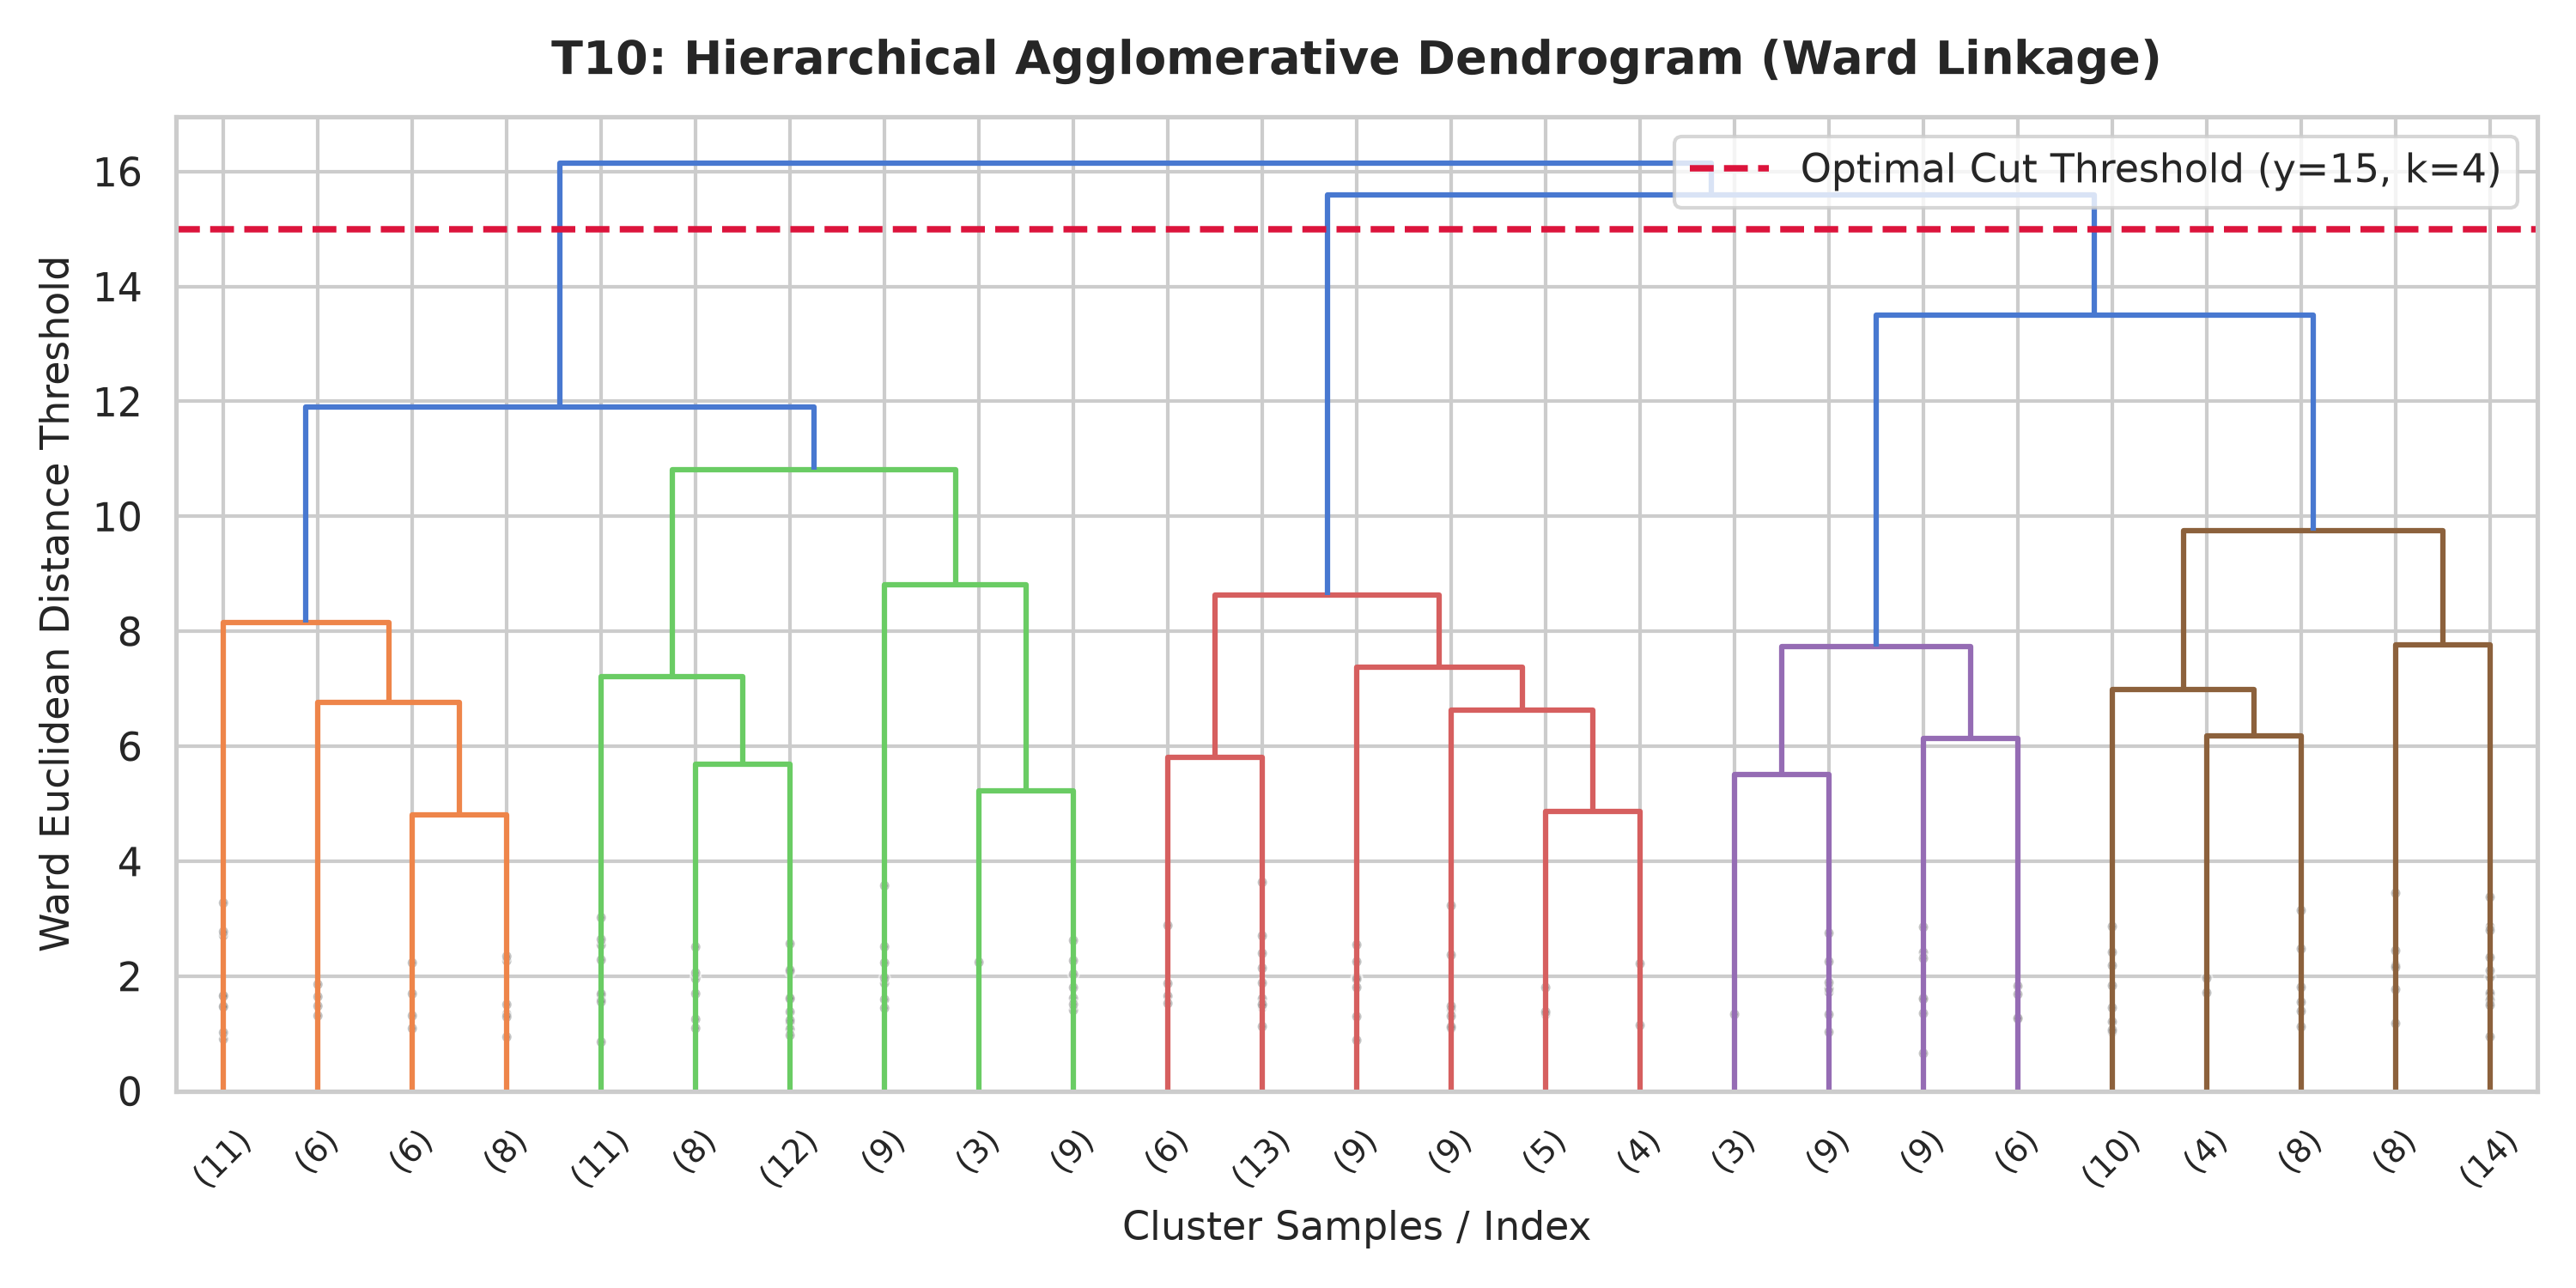

In [3]:
# Step 3: Compute Linkage Matrix and Render Dendrogram
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5), dpi=300)
dendrogram(linkage_matrix, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=9, show_contracted=True)
plt.title("T10: Hierarchical Agglomerative Dendrogram (Ward Linkage)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cluster Samples / Index", fontsize=11)
plt.ylabel("Ward Euclidean Distance Threshold", fontsize=11)
plt.axhline(y=15, color='crimson', linestyle='--', linewidth=1.8, label='Optimal Cut Threshold (y=15, k=4)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


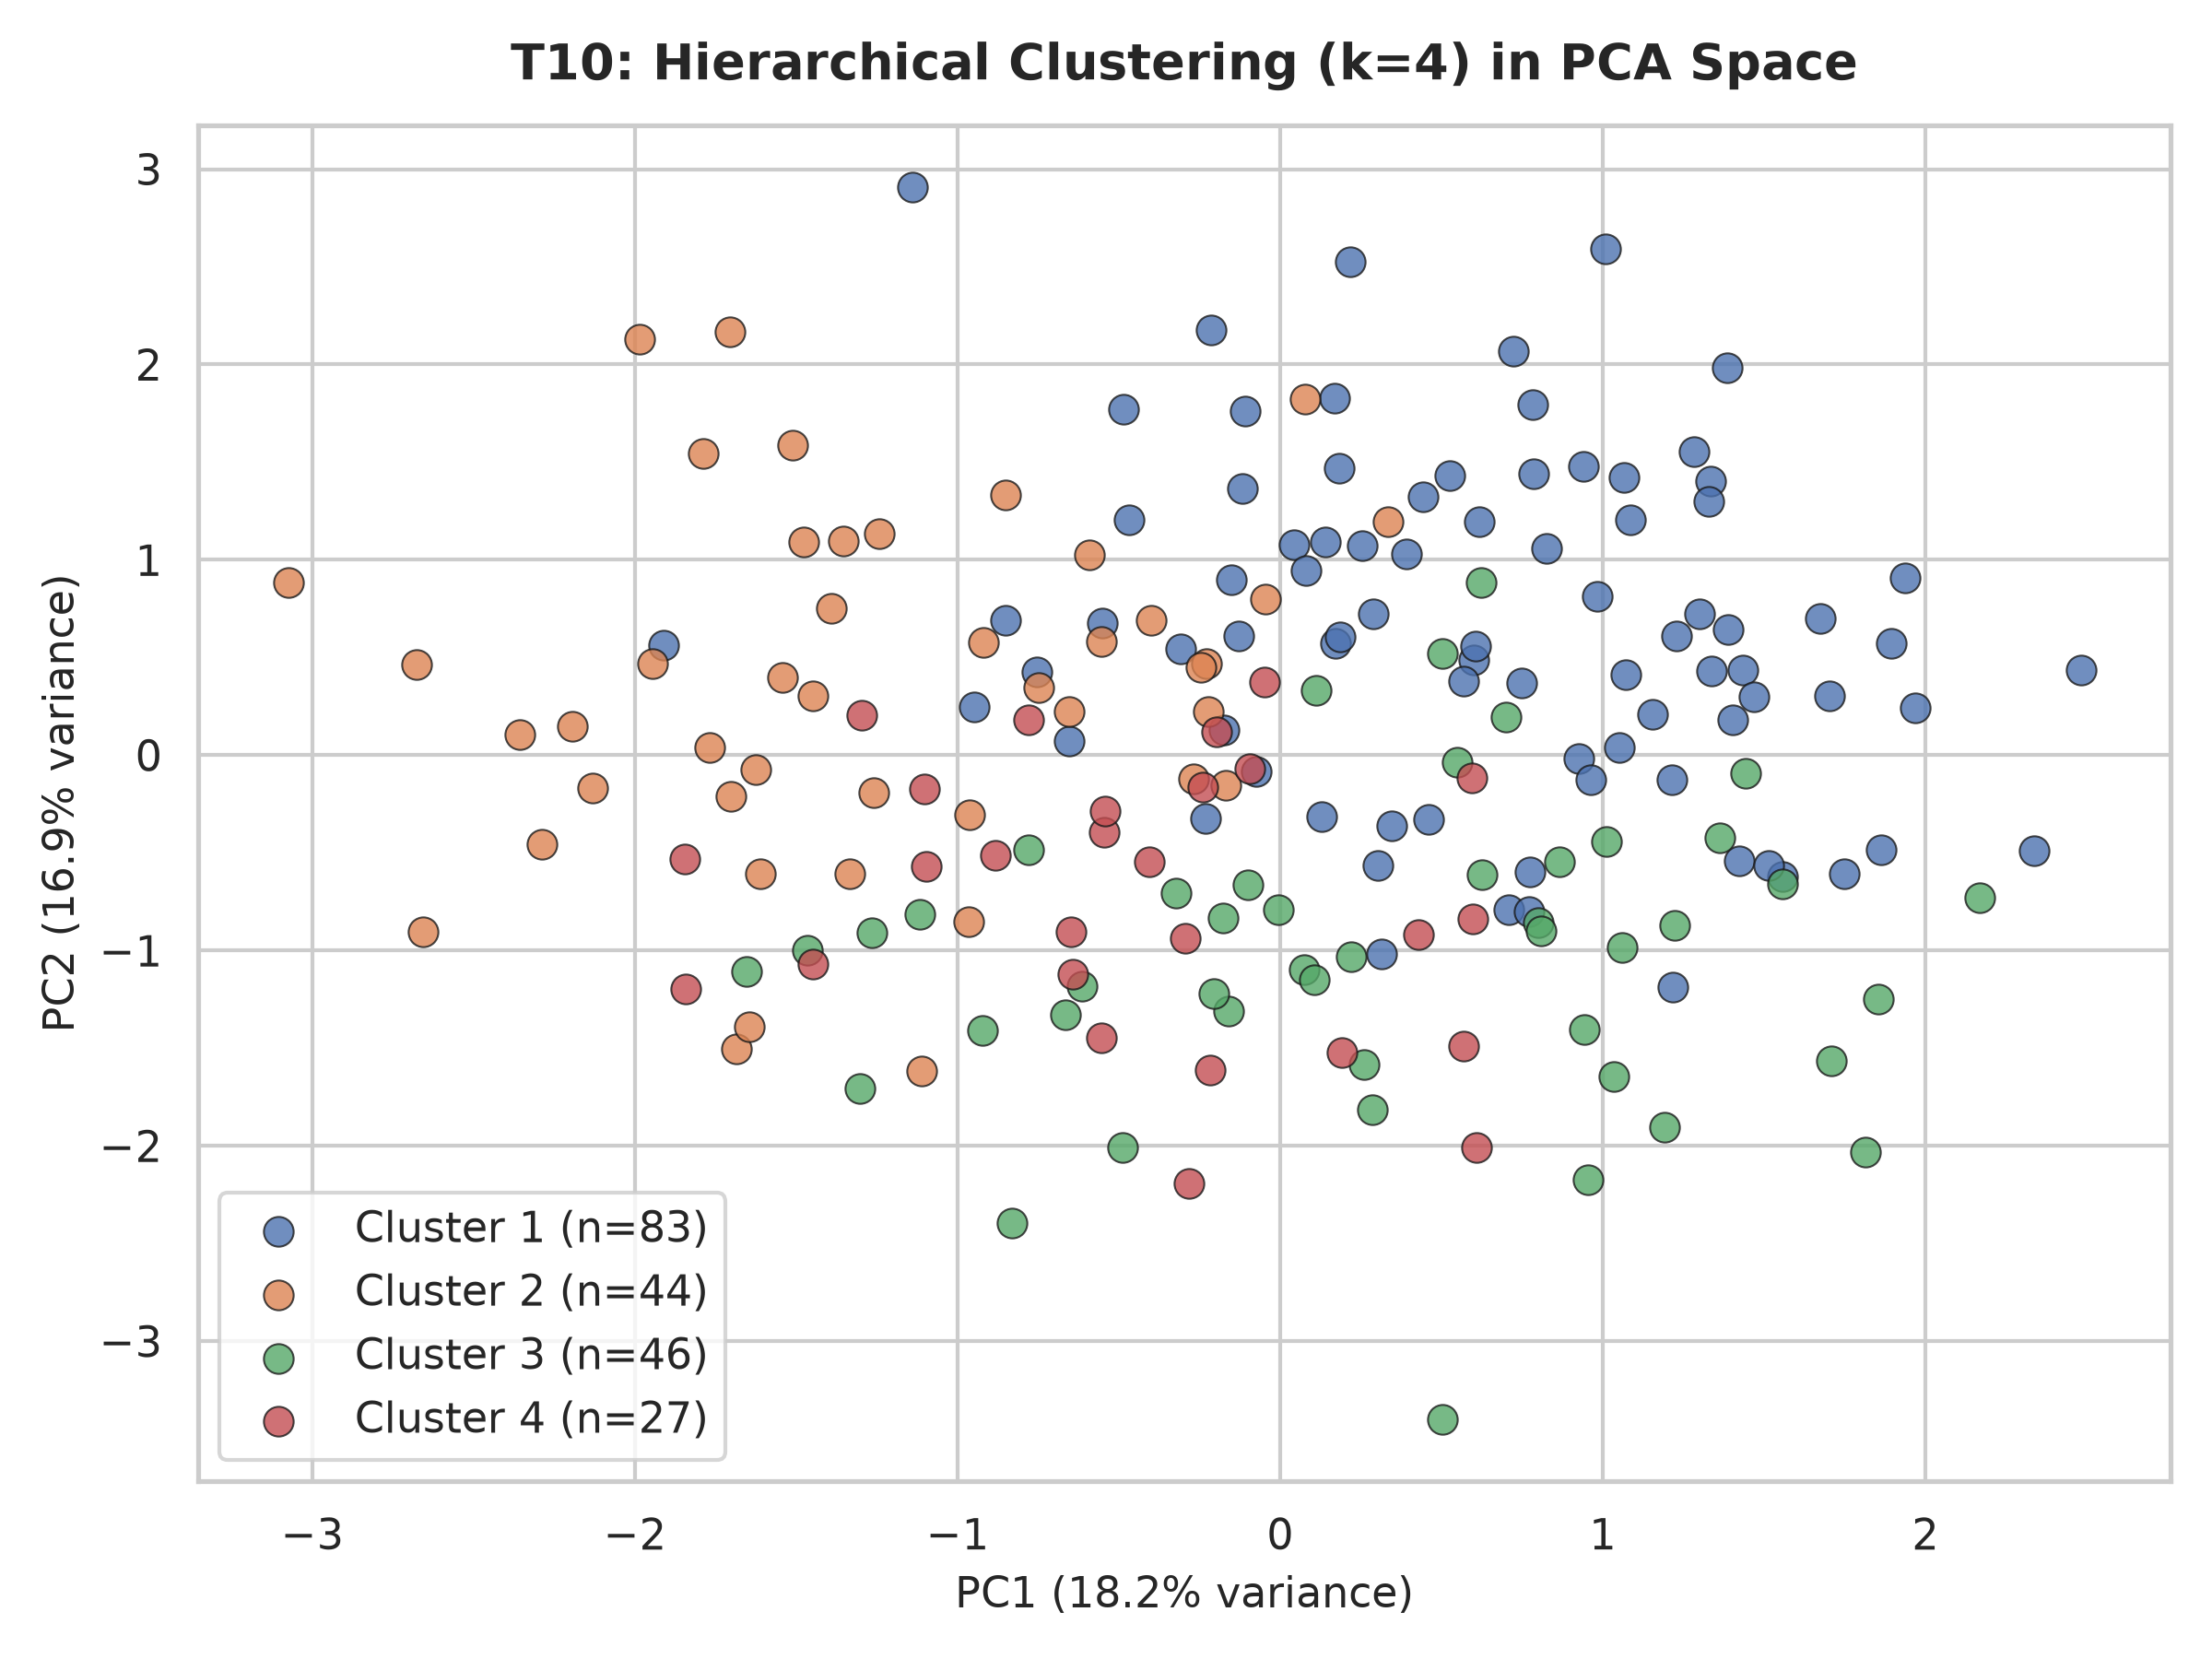

In [4]:
# Step 4: Fit Agglomerative Clustering & Visualize in 2D PCA Space
k_clusters = 4
agg_model = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6), dpi=300)
palette = sns.color_palette("deep", k_clusters)
for c in range(k_clusters):
    idx = (agg_labels == c)
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f"Cluster {c+1} (n={idx.sum()})", color=palette[c], alpha=0.8, s=60, edgecolors='k', linewidth=0.5)

plt.title(f"T10: Hierarchical Clustering (k={k_clusters}) in PCA Space", fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)", fontsize=11)
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)", fontsize=11)
plt.legend(loc='best', frameon=True)
plt.tight_layout()
plt.show()


In [5]:
# Step 5: Profile Discovered Clusters across Soil & Weather Attributes
df_profile = pd.DataFrame(X_raw, columns=feature_cols)
df_profile['Cluster'] = agg_labels + 1
profile_summary = df_profile.groupby('Cluster').mean().round(2)
profile_summary['Sample_Count'] = df_profile['Cluster'].value_counts()
print("=== Cluster Agronomic Mean Profiles ===")
display(profile_summary)

sil = silhouette_score(X_scaled, agg_labels)
print(f"\nOverall Silhouette Score for Hierarchical Clustering: {sil:.4f}")


=== Cluster Agronomic Mean Profiles ===
Overall Silhouette Score for Hierarchical Clustering: 0.0977


### 🧠 Viva Voce & Conceptual Questions (T10):
1. **Q: What is the fundamental difference between Agglomerative and Divisive clustering?**
   - **A:** Agglomerative is a bottom-up approach where each observation starts as its own cluster and pairs merge iteratively. Divisive is top-down, starting with all points in one large cluster and recursively splitting.
2. **Q: How does Ward's linkage criterion work mathematically?**
   - **A:** Ward's method minimizes the total within-cluster variance. At each step, it merges the pair of clusters that leads to the minimum increase in the sum of squared Euclidean distances from the centroid:
   $$\Delta ESS_{AB} = \frac{n_A n_B}{n_A + n_B} ||\mu_A - \mu_B||^2$$
3. **Q: Why is feature scaling mandatory before computing linkage?**
   - **A:** Euclidean distance is scale-sensitive. Without scaling, high-magnitude features like Nitrogen (0-140) or Rainfall (20-300 mm) would completely overwhelm pH (3.5-9.0), distorting distance calculations.




---
# 🚀 CHAPTER: T11: K-MEANS CLUSTERING
---


In [1]:
# Step 1: Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
print("✅ Libraries loaded.")


✅ Libraries loaded.


In [2]:
# Step 2: Load Data and Standardize
df = pd.read_csv("data/Crop_recommendation.csv")
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X_raw = df[feature_cols].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print(f"Data scaled: {X_scaled.shape}")


Data scaled: (200, 7)


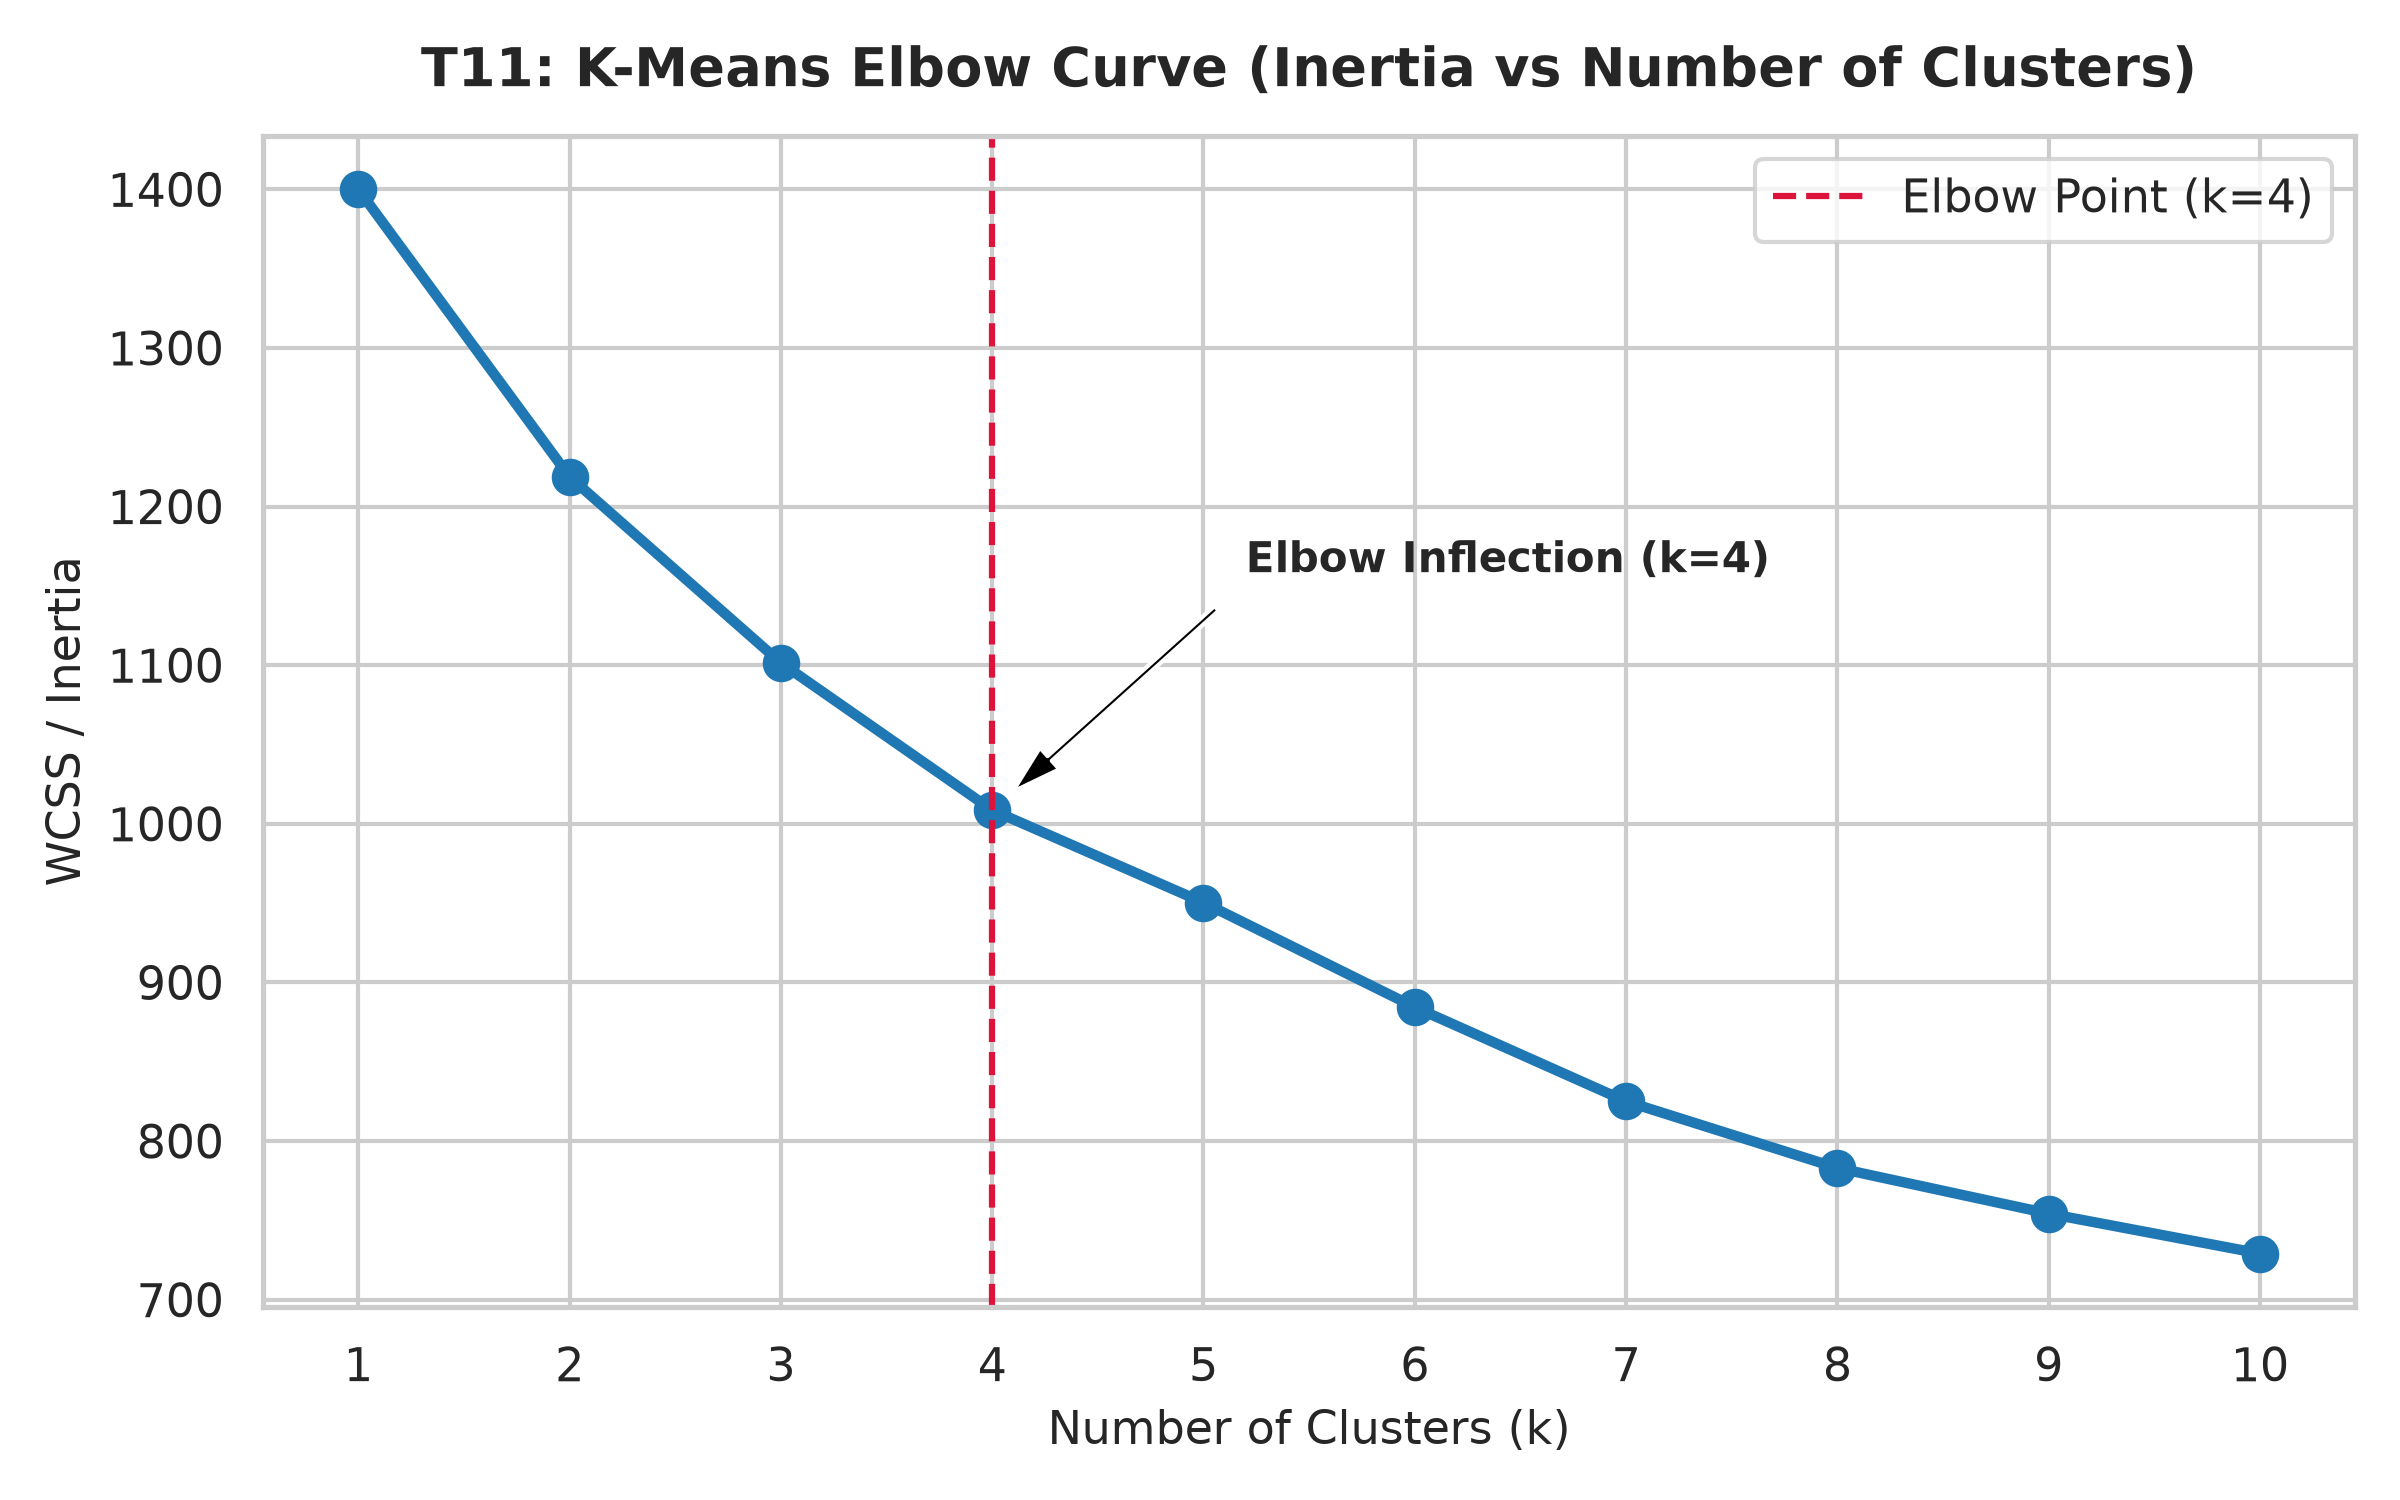

In [3]:
# Step 3: Run Elbow Method (WCSS / Inertia across K=1 to 10)
k_range = range(1, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5), dpi=300)
plt.plot(list(k_range), inertias, marker='o', color='#1f77b4', linewidth=2.5, markersize=8)
plt.title("T11: K-Means Elbow Curve (Inertia vs Number of Clusters)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Number of Clusters (k)", fontsize=11)
plt.ylabel("WCSS / Inertia", fontsize=11)
plt.xticks(list(k_range))
plt.axvline(x=4, color='crimson', linestyle='--', linewidth=1.5, label='Elbow Inflection (k=4)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


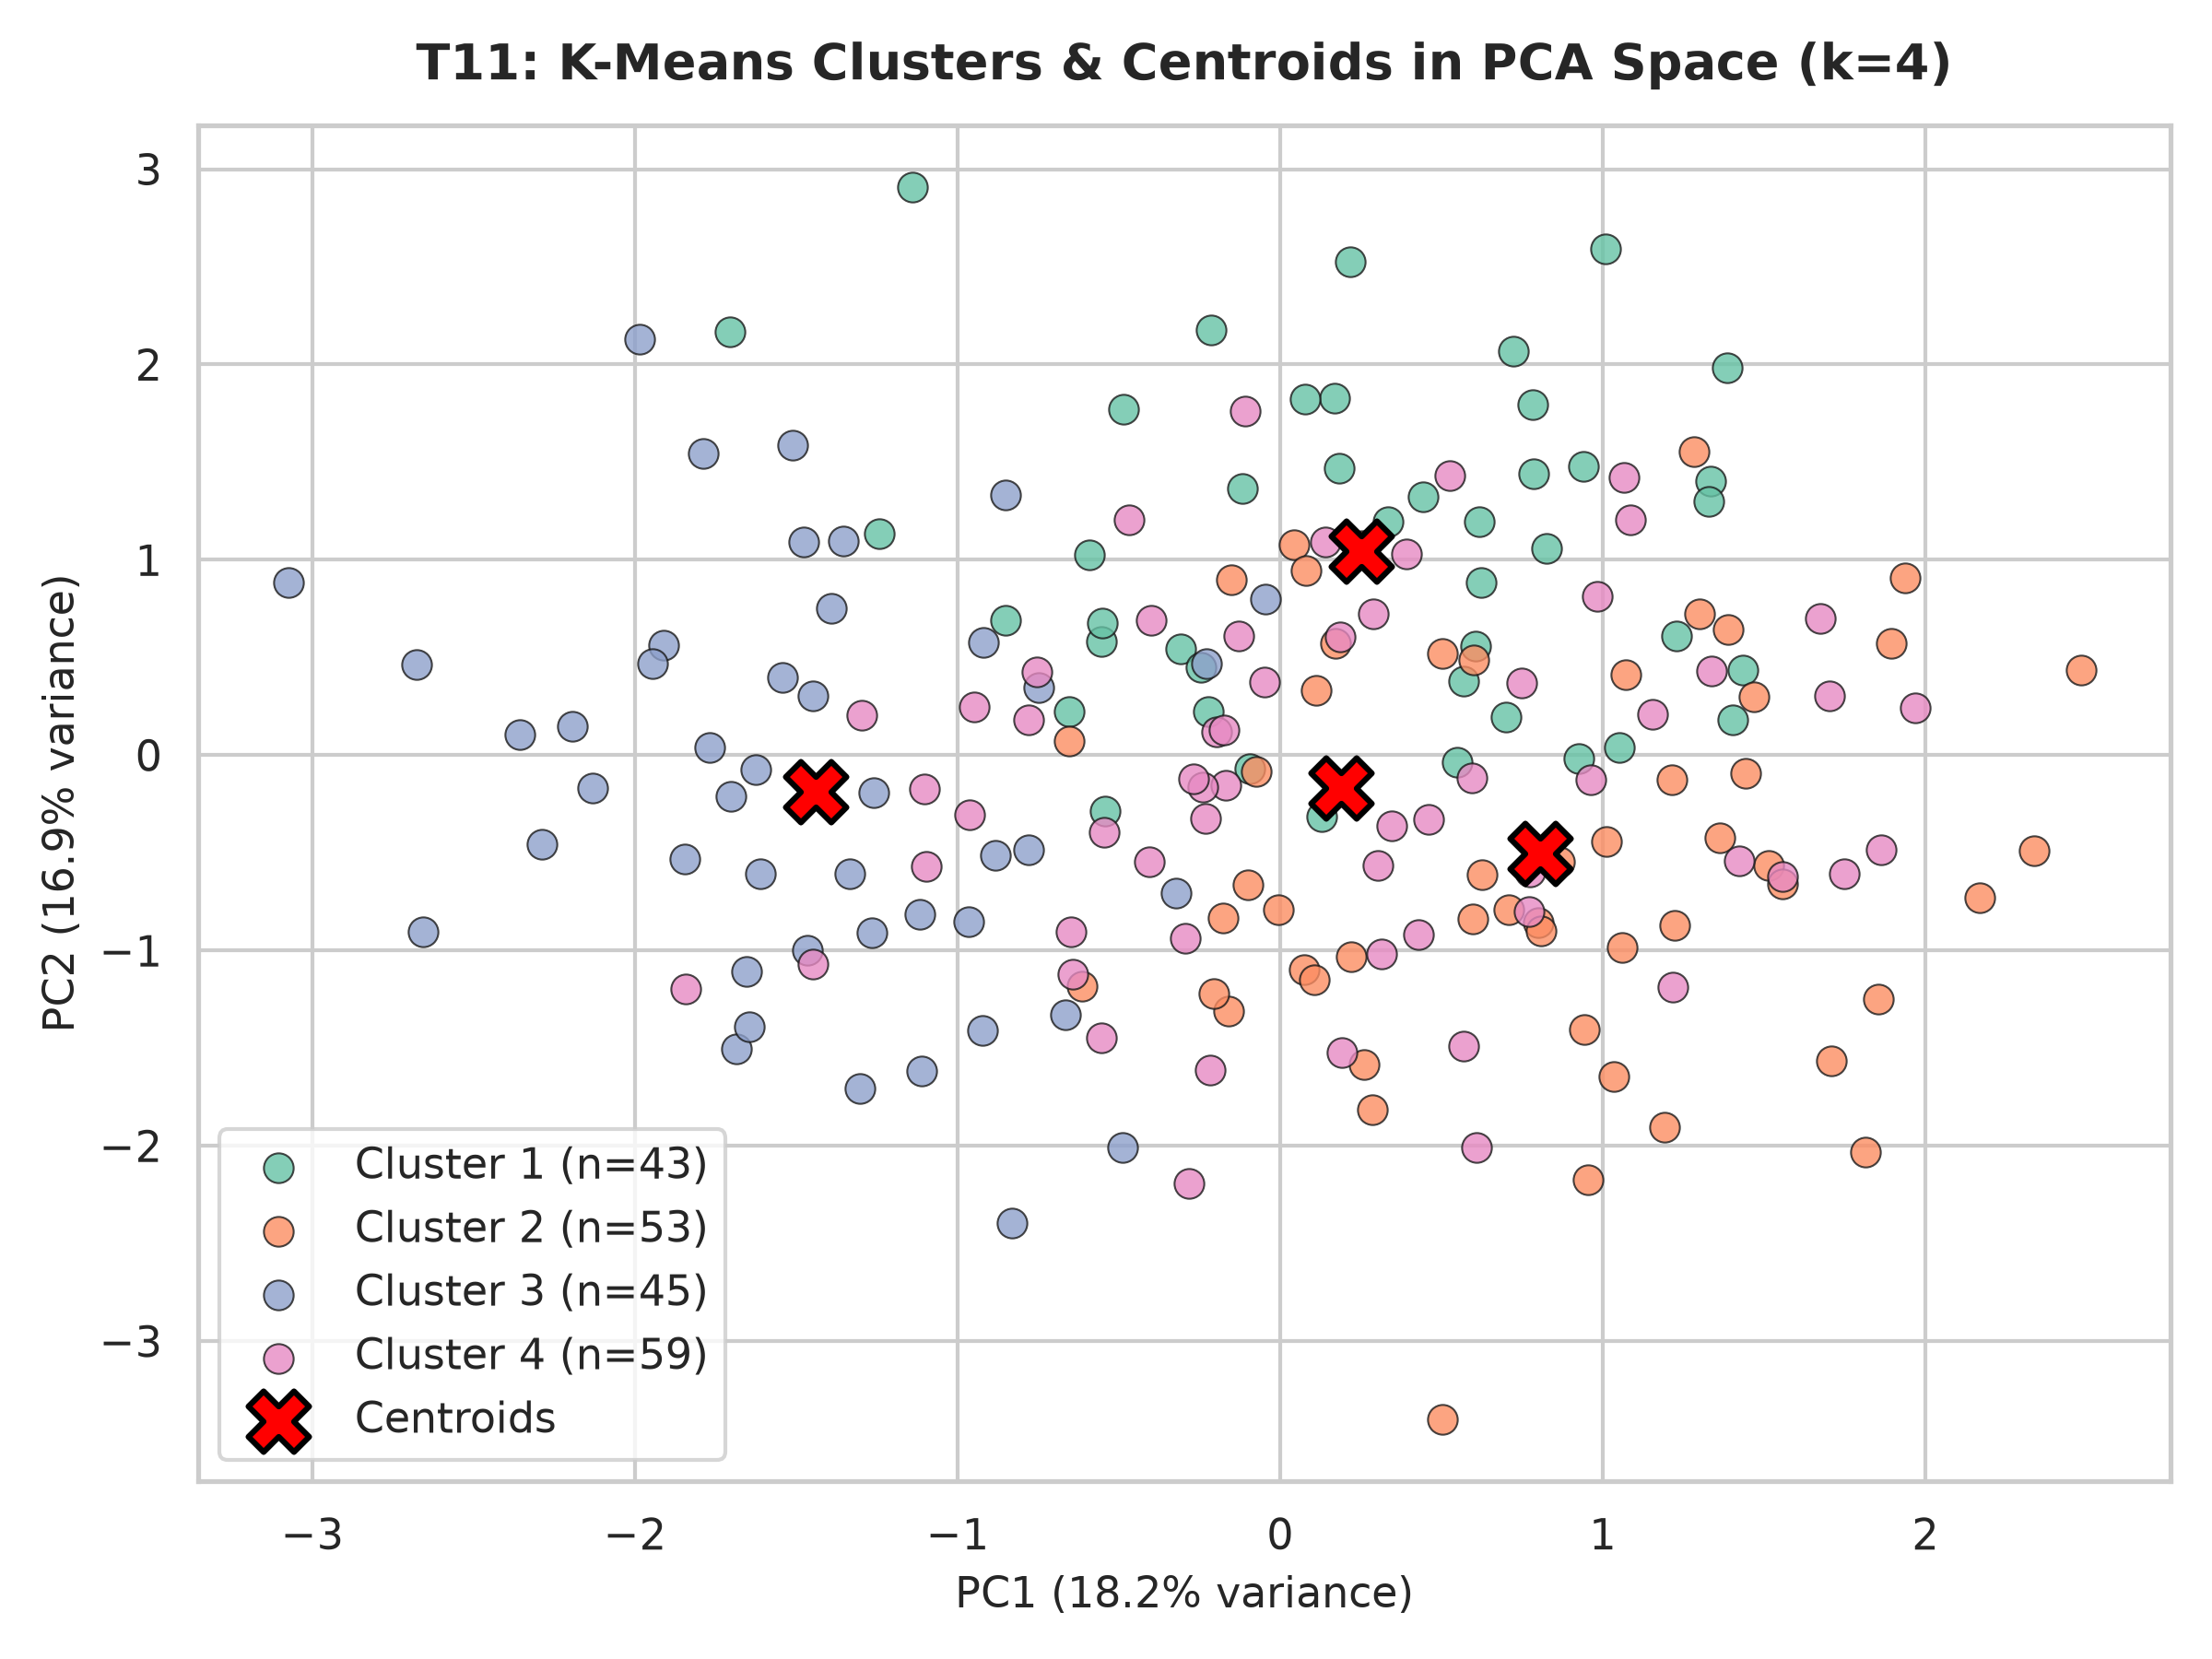

In [4]:
# Step 4: Fit Optimal K-Means (k=4) and Plot Centroids in PCA Space
k_optimal = 4
kmeans_model = KMeans(n_clusters=k_optimal, init='k-means++', n_init=10, random_state=42)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
kmeans_centers_pca = pca.transform(kmeans_model.cluster_centers_)

plt.figure(figsize=(8, 6), dpi=300)
palette = sns.color_palette("Set2", k_optimal)
for c in range(k_optimal):
    idx = (kmeans_labels == c)
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=f"Cluster {c+1} (n={idx.sum()})", color=palette[c], alpha=0.8, s=60, edgecolors='k', linewidth=0.5)

plt.scatter(kmeans_centers_pca[:, 0], kmeans_centers_pca[:, 1], s=250, c='red', marker='X', edgecolor='black', linewidth=1.5, label='Centroids', zorder=10)
plt.title(f"T11: K-Means Clusters & Centroids in PCA Space (k={k_optimal})", fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)", fontsize=11)
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)", fontsize=11)
plt.legend(loc='best', frameon=True)
plt.tight_layout()
plt.show()


In [5]:
# Step 5: Inverse Transform Centroids to Physical Agronomic Scale
centers_orig = scaler.inverse_transform(kmeans_model.cluster_centers_)
df_centers = pd.DataFrame(centers_orig, columns=feature_cols, index=[f"Cluster {i+1}" for i in range(k_optimal)]).round(2)
print("=== K-Means Cluster Centroids (Physical Units) ===")
display(df_centers)

sil = silhouette_score(X_scaled, kmeans_labels)
print(f"\nFinal Inertia: {kmeans_model.inertia_:.2f}")
print(f"K-Means Silhouette Score: {sil:.4f}")


=== K-Means Cluster Centroids (Physical Units) ===
Final Inertia: 1008.67
K-Means Silhouette Score: 0.1212


### 🧠 Viva Voce & Conceptual Questions (T11):
1. **Q: What is the objective function optimized by K-Means?**
   - **A:** K-Means minimizes the Within-Cluster Sum of Squares (Inertia):
   $$J = \sum_{j=1}^{k} \sum_{x_i \in S_j} ||x_i - \mu_j||^2$$
2. **Q: How does `k-means++` initialization differ from standard random initialization?**
   - **A:** Standard K-Means picks $k$ centroids completely at random, which can cause poor local minima. `k-means++` picks the first centroid at random, then selects subsequent centroids with probability proportional to the squared distance to the nearest existing centroid ($P(x) \propto D(x)^2$). This spreads initial centroids out and provides an $O(\log k)$ competitive bound.
3. **Q: Does K-Means always converge to the global optimum?**
   - **A:** No, Lloyd's algorithm is a heuristic that is guaranteed to converge to a *local* minimum, which is why running with multiple initializations (`n_init=10`) is essential.




---
# 🚀 CHAPTER: T12: CLUSTER EVALUATION
---


In [1]:
# Step 1: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score
)

sns.set_theme(style="whitegrid")
print("✅ Evaluation metrics imported.")


✅ Evaluation metrics imported.


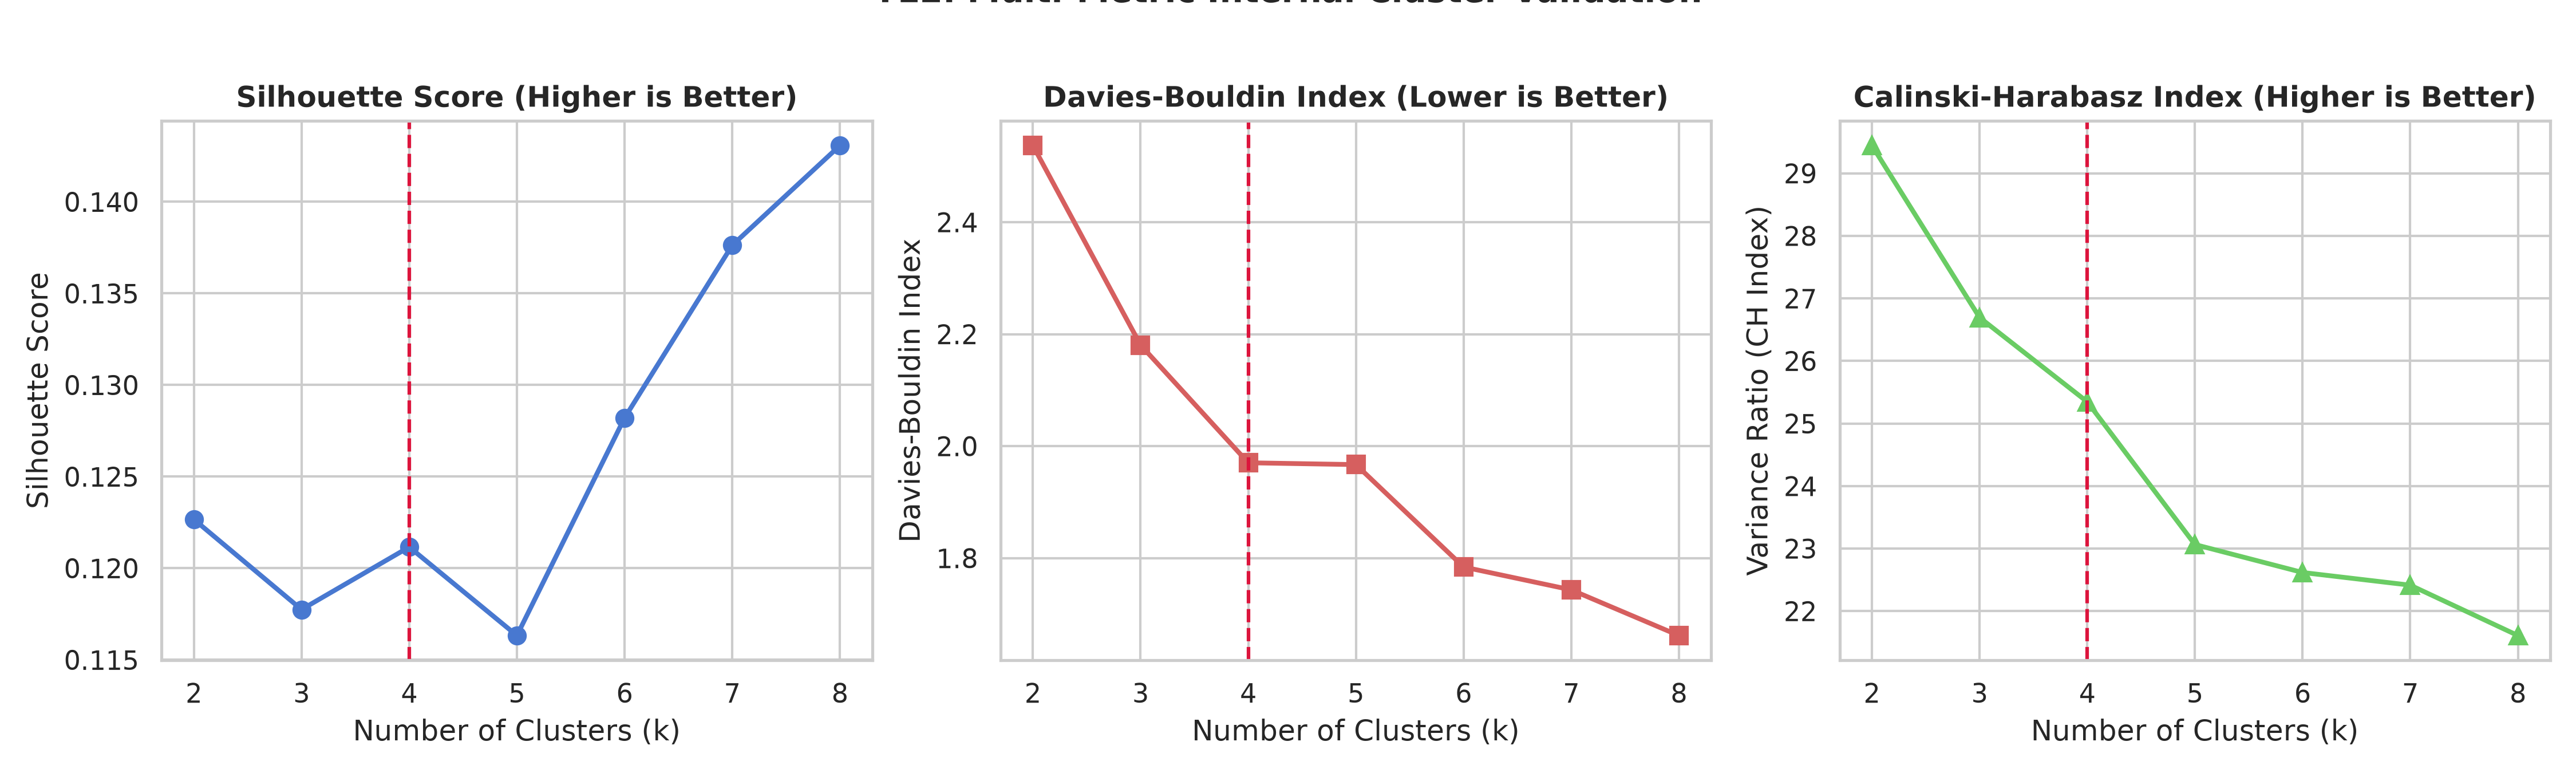

In [2]:
# Step 2: Load Data and Compute Internal Metrics across K=2 to 8
df = pd.read_csv("data/Crop_recommendation.csv")
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X_scaled = StandardScaler().fit_transform(df[feature_cols].values)

k_range = range(2, 9)
sil_scores = []
db_scores = []
ch_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    lbls = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, lbls))
    db_scores.append(davies_bouldin_score(X_scaled, lbls))
    ch_scores.append(calinski_harabasz_score(X_scaled, lbls))

# Multi-metric internal validation curves
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)
ax1.plot(list(k_range), sil_scores, 'bo-', linewidth=2, markersize=7)
ax1.set_title("Silhouette Score (Higher is Better)", fontweight='bold')
ax1.set_xlabel("Number of Clusters (k)")
ax1.axvline(x=4, color='crimson', linestyle='--')

ax2.plot(list(k_range), db_scores, 'rs-', linewidth=2, markersize=7)
ax2.set_title("Davies-Bouldin Index (Lower is Better)", fontweight='bold')
ax2.set_xlabel("Number of Clusters (k)")
ax2.axvline(x=4, color='crimson', linestyle='--')

ax3.plot(list(k_range), ch_scores, 'g^-', linewidth=2, markersize=7)
ax3.set_title("Calinski-Harabasz Index (Higher is Better)", fontweight='bold')
ax3.set_xlabel("Number of Clusters (k)")
ax3.axvline(x=4, color='crimson', linestyle='--')

plt.suptitle("T12: Multi-Metric Internal Cluster Validation", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


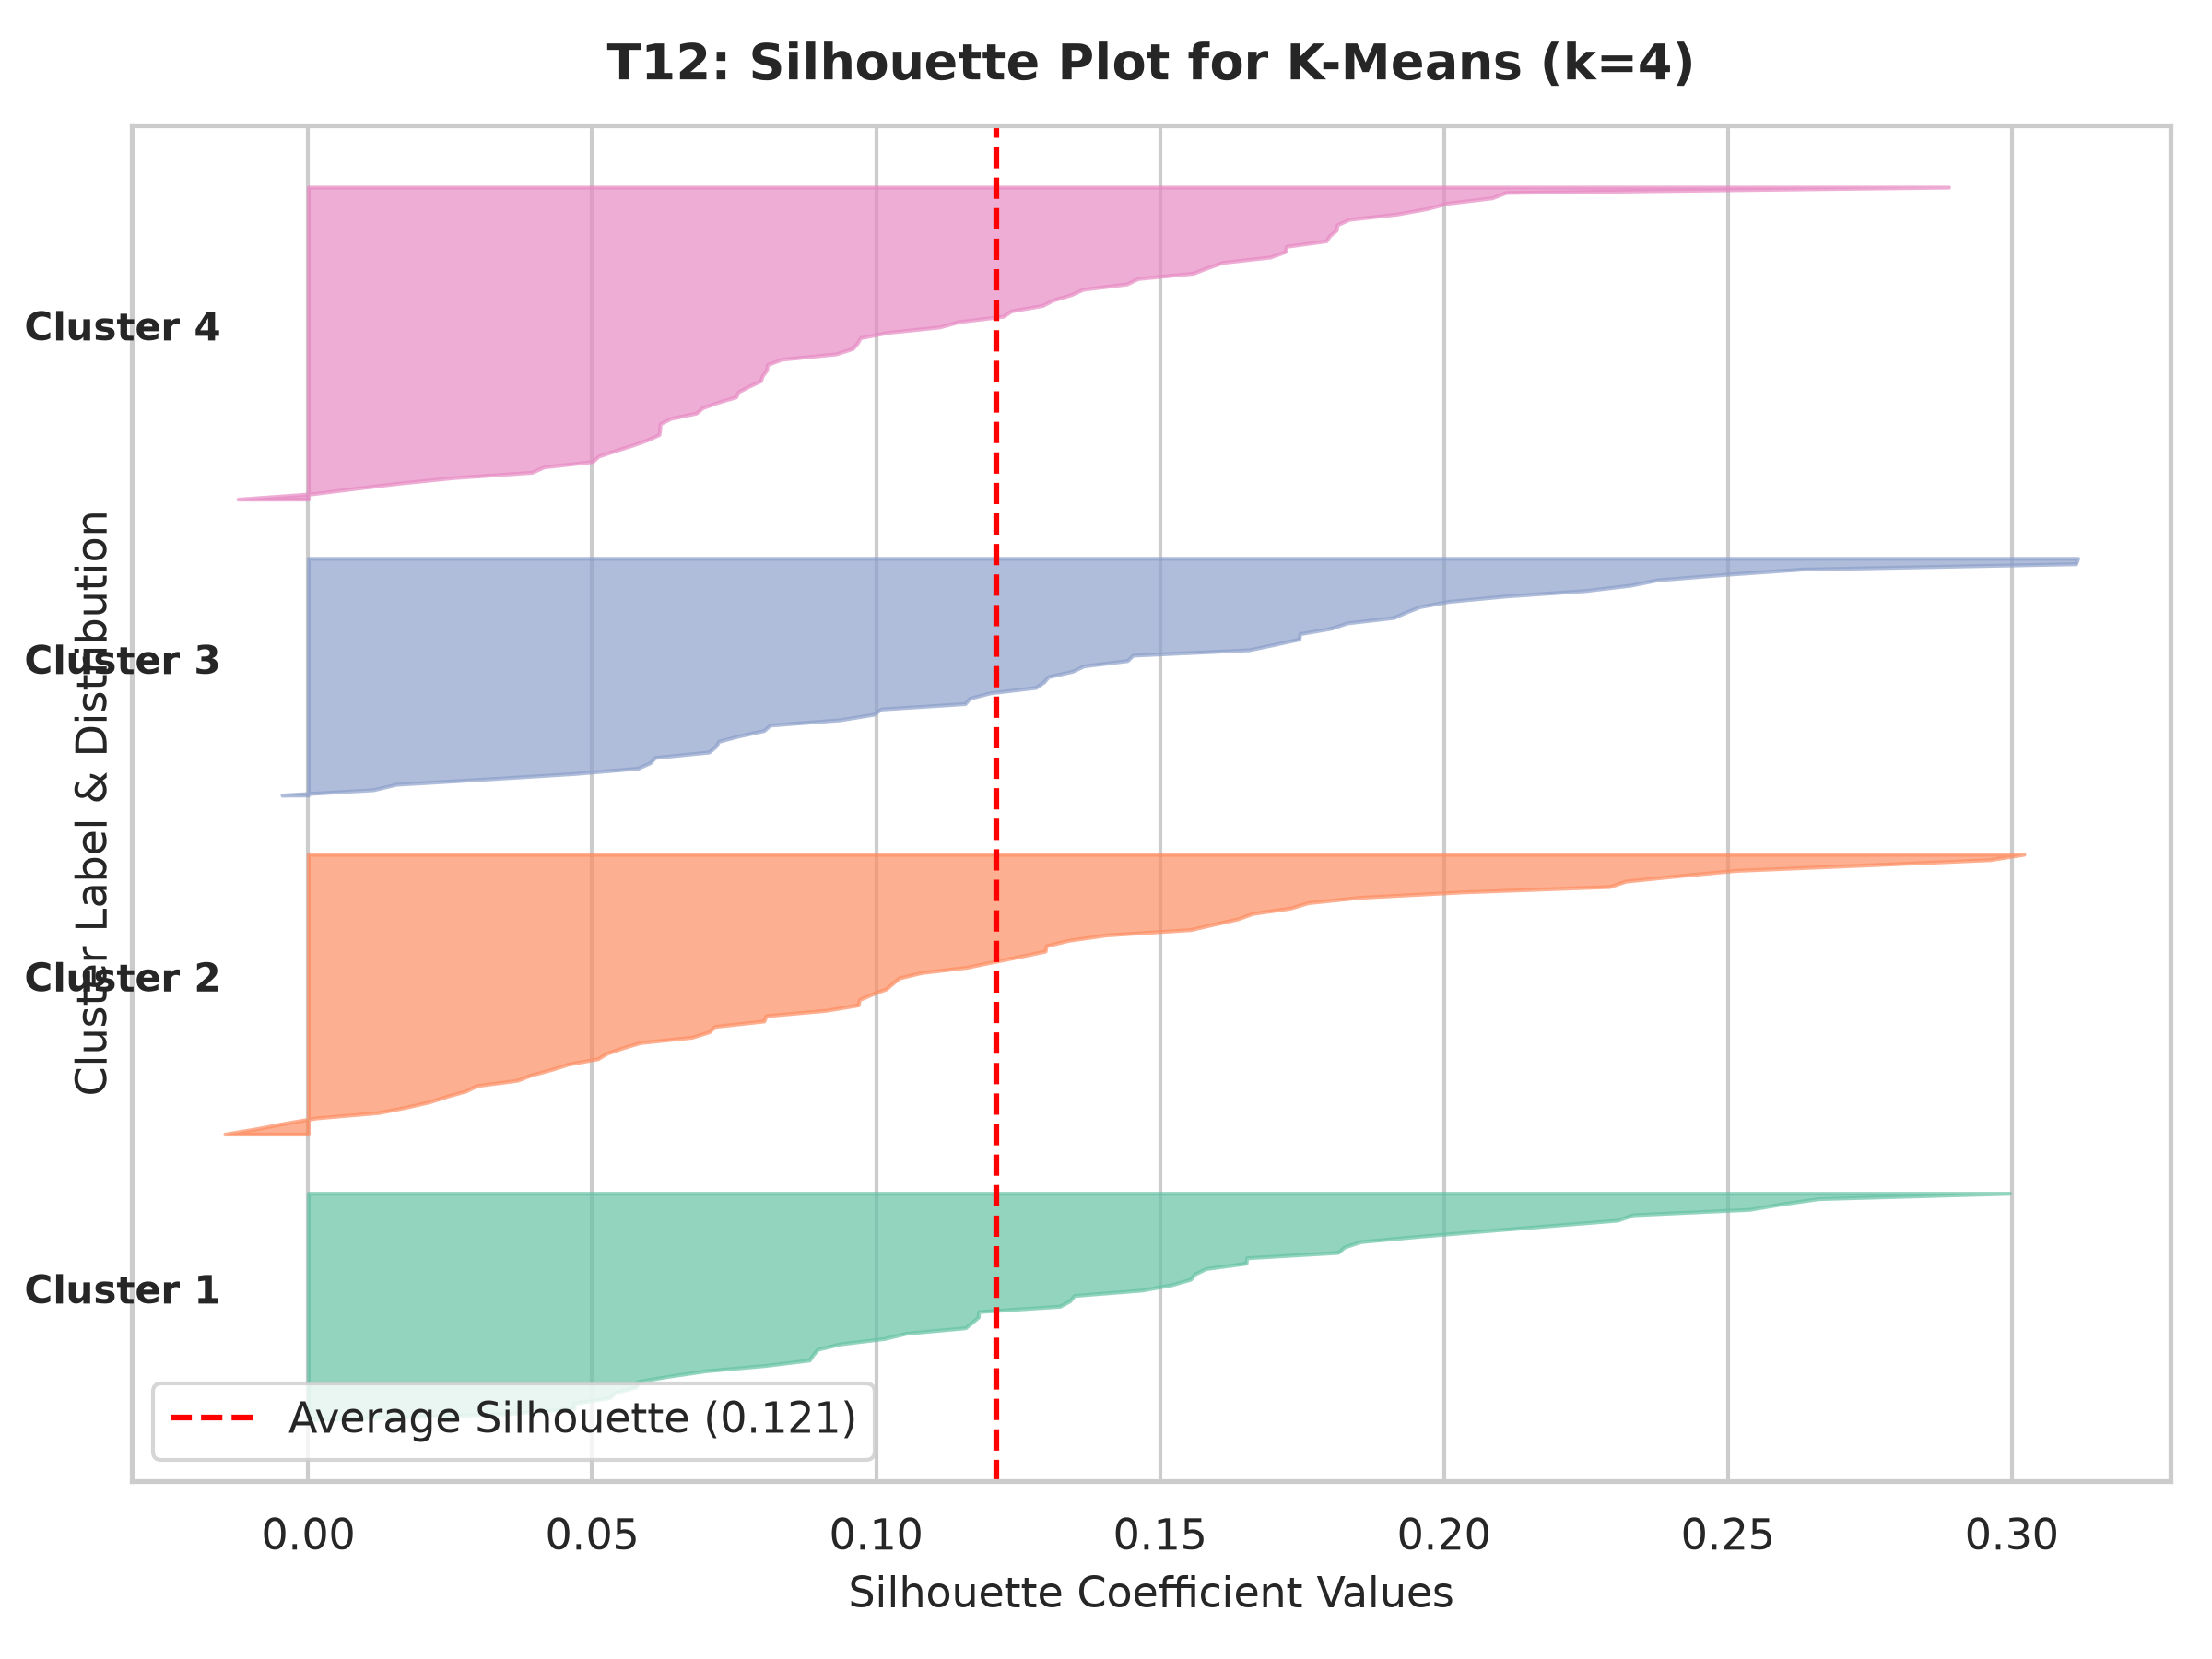

In [3]:
# Step 3: Detailed Silhouette Sample-Level Diagram (k=4)
k_eval = 4
km_eval = KMeans(n_clusters=k_eval, init='k-means++', n_init=10, random_state=42)
km_lbls = km_eval.fit_predict(X_scaled)
sample_sil_values = silhouette_samples(X_scaled, km_lbls)
avg_sil = silhouette_score(X_scaled, km_lbls)

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
palette = sns.color_palette("Set2", k_eval)
y_lower = 10
for i in range(k_eval):
    ith_cluster_sil = sample_sil_values[km_lbls == i]
    ith_cluster_sil.sort()
    size_i = ith_cluster_sil.shape[0]
    y_upper = y_lower + size_i
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil, facecolor=palette[i], edgecolor=palette[i], alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_i, f"Cluster {i+1}", fontsize=10, fontweight='bold')
    y_lower = y_upper + 10

ax.set_title("T12: Silhouette Plot for K-Means (k=4)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Silhouette Coefficient Values", fontsize=11)
ax.set_ylabel("Cluster Distribution", fontsize=11)
ax.axvline(x=avg_sil, color="red", linestyle="--", linewidth=1.5, label=f"Average Silhouette ({avg_sil:.3f})")
ax.set_yticks([])
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()


In [4]:
# Step 4: Full Comparative Evaluation Table (Internal & External Metrics)
y_true = LabelEncoder().fit_transform(df['label'].values)
agg_lbls = AgglomerativeClustering(n_clusters=4, linkage='ward').fit_predict(X_scaled)

eval_data = {
    'Evaluation Metric': [
        'Silhouette Score (Internal)',
        'Davies-Bouldin Index (Internal)',
        'Calinski-Harabasz Index (Internal)',
        'Adjusted Rand Index - ARI (External)',
        'Normalized Mutual Information - NMI (External)',
        'Homogeneity Score (External)',
        'Completeness Score (External)',
        'V-Measure Score (External)'
    ],
    'K-Means (k=4)': [
        round(silhouette_score(X_scaled, km_lbls), 4),
        round(davies_bouldin_score(X_scaled, km_lbls), 4),
        round(calinski_harabasz_score(X_scaled, km_lbls), 2),
        round(adjusted_rand_score(y_true, km_lbls), 4),
        round(normalized_mutual_info_score(y_true, km_lbls), 4),
        round(homogeneity_score(y_true, km_lbls), 4),
        round(completeness_score(y_true, km_lbls), 4),
        round(v_measure_score(y_true, km_lbls), 4)
    ],
    'Hierarchical (k=4)': [
        round(silhouette_score(X_scaled, agg_lbls), 4),
        round(davies_bouldin_score(X_scaled, agg_lbls), 4),
        round(calinski_harabasz_score(X_scaled, agg_lbls), 2),
        round(adjusted_rand_score(y_true, agg_lbls), 4),
        round(normalized_mutual_info_score(y_true, agg_lbls), 4),
        round(homogeneity_score(y_true, agg_lbls), 4),
        round(completeness_score(y_true, agg_lbls), 4),
        round(v_measure_score(y_true, agg_lbls), 4)
    ]
}

df_eval_summary = pd.DataFrame(eval_data)
display(df_eval_summary)


Metric  K-Means (k=4)  Hierarchical (k=4)
                   Silhouette Score (Internal)         0.1212              0.0977
               Davies-Bouldin Index (Internal)         1.9703              2.1341
            Calinski-Harabasz Index (Internal)        25.3500             21.2000
          Adjusted Rand Index - ARI (External)         0.0098              0.0013
Normalized Mutual Information - NMI (External)         0.0471              0.0329
                  Homogeneity Score (External)         0.0377              0.0258
                 Completeness Score (External)         0.0626              0.0452
                    V-Measure Score (External)         0.0471              0.0329


### 🧠 Viva Voce & Conceptual Questions (T12):
1. **Q: What does a negative Silhouette Coefficient indicate?**
   - **A:** The silhouette coefficient is defined as:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance. If $s(i) < 0$, sample $i$ is closer to neighboring clusters than to its own assigned cluster, indicating sample misassignment.
2. **Q: Why does a lower Davies-Bouldin index indicate superior clustering?**
   - **A:** The DB index measures the similarity between each cluster and its most similar rival:
   $$R_{ij} = \frac{s_i + s_j}{d(\mu_i, \mu_j)}$$
   A lower DB index signifies compact, tightly packed clusters ($s_i$ small) that are well-separated from one another ($d(\mu_i, \mu_j)$ large).
3. **Q: What is the purpose of the Adjusted Rand Index (ARI)?**
   - **A:** The raw Rand Index counts sample pairs assigned together or separately. The *Adjusted* Rand Index corrects for the probability of chance agreement, yielding values between -1 and 1, where 0 represents completely random clustering.




---
# 🚀 CHAPTER: T13: DECISION TREE ALGORITHM
---


In [1]:
# Step 1: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
print("✅ Decision Tree libraries loaded.")


✅ Decision Tree libraries loaded.


In [2]:
# Step 2: Load Data and Create Stratified Train-Test Split (80/20)
df = pd.read_csv("data/Crop_recommendation.csv")
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[feature_cols].values
le = LabelEncoder()
y = le.fit_transform(df['label'].values)
classes = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training Samples: {X_train.shape[0]}, Testing Samples: {X_test.shape[0]}")
print(f"Target Classes ({len(classes)}): {classes.tolist()}")


Training Samples: 160, Testing Samples: 40
Target Classes (10): ['blackgram', 'chickpea', 'kidneybeans', 'lentil', 'maize', 'mothbeans', 'mungbean', 'pigeonpeas', 'pomegranate', 'rice']


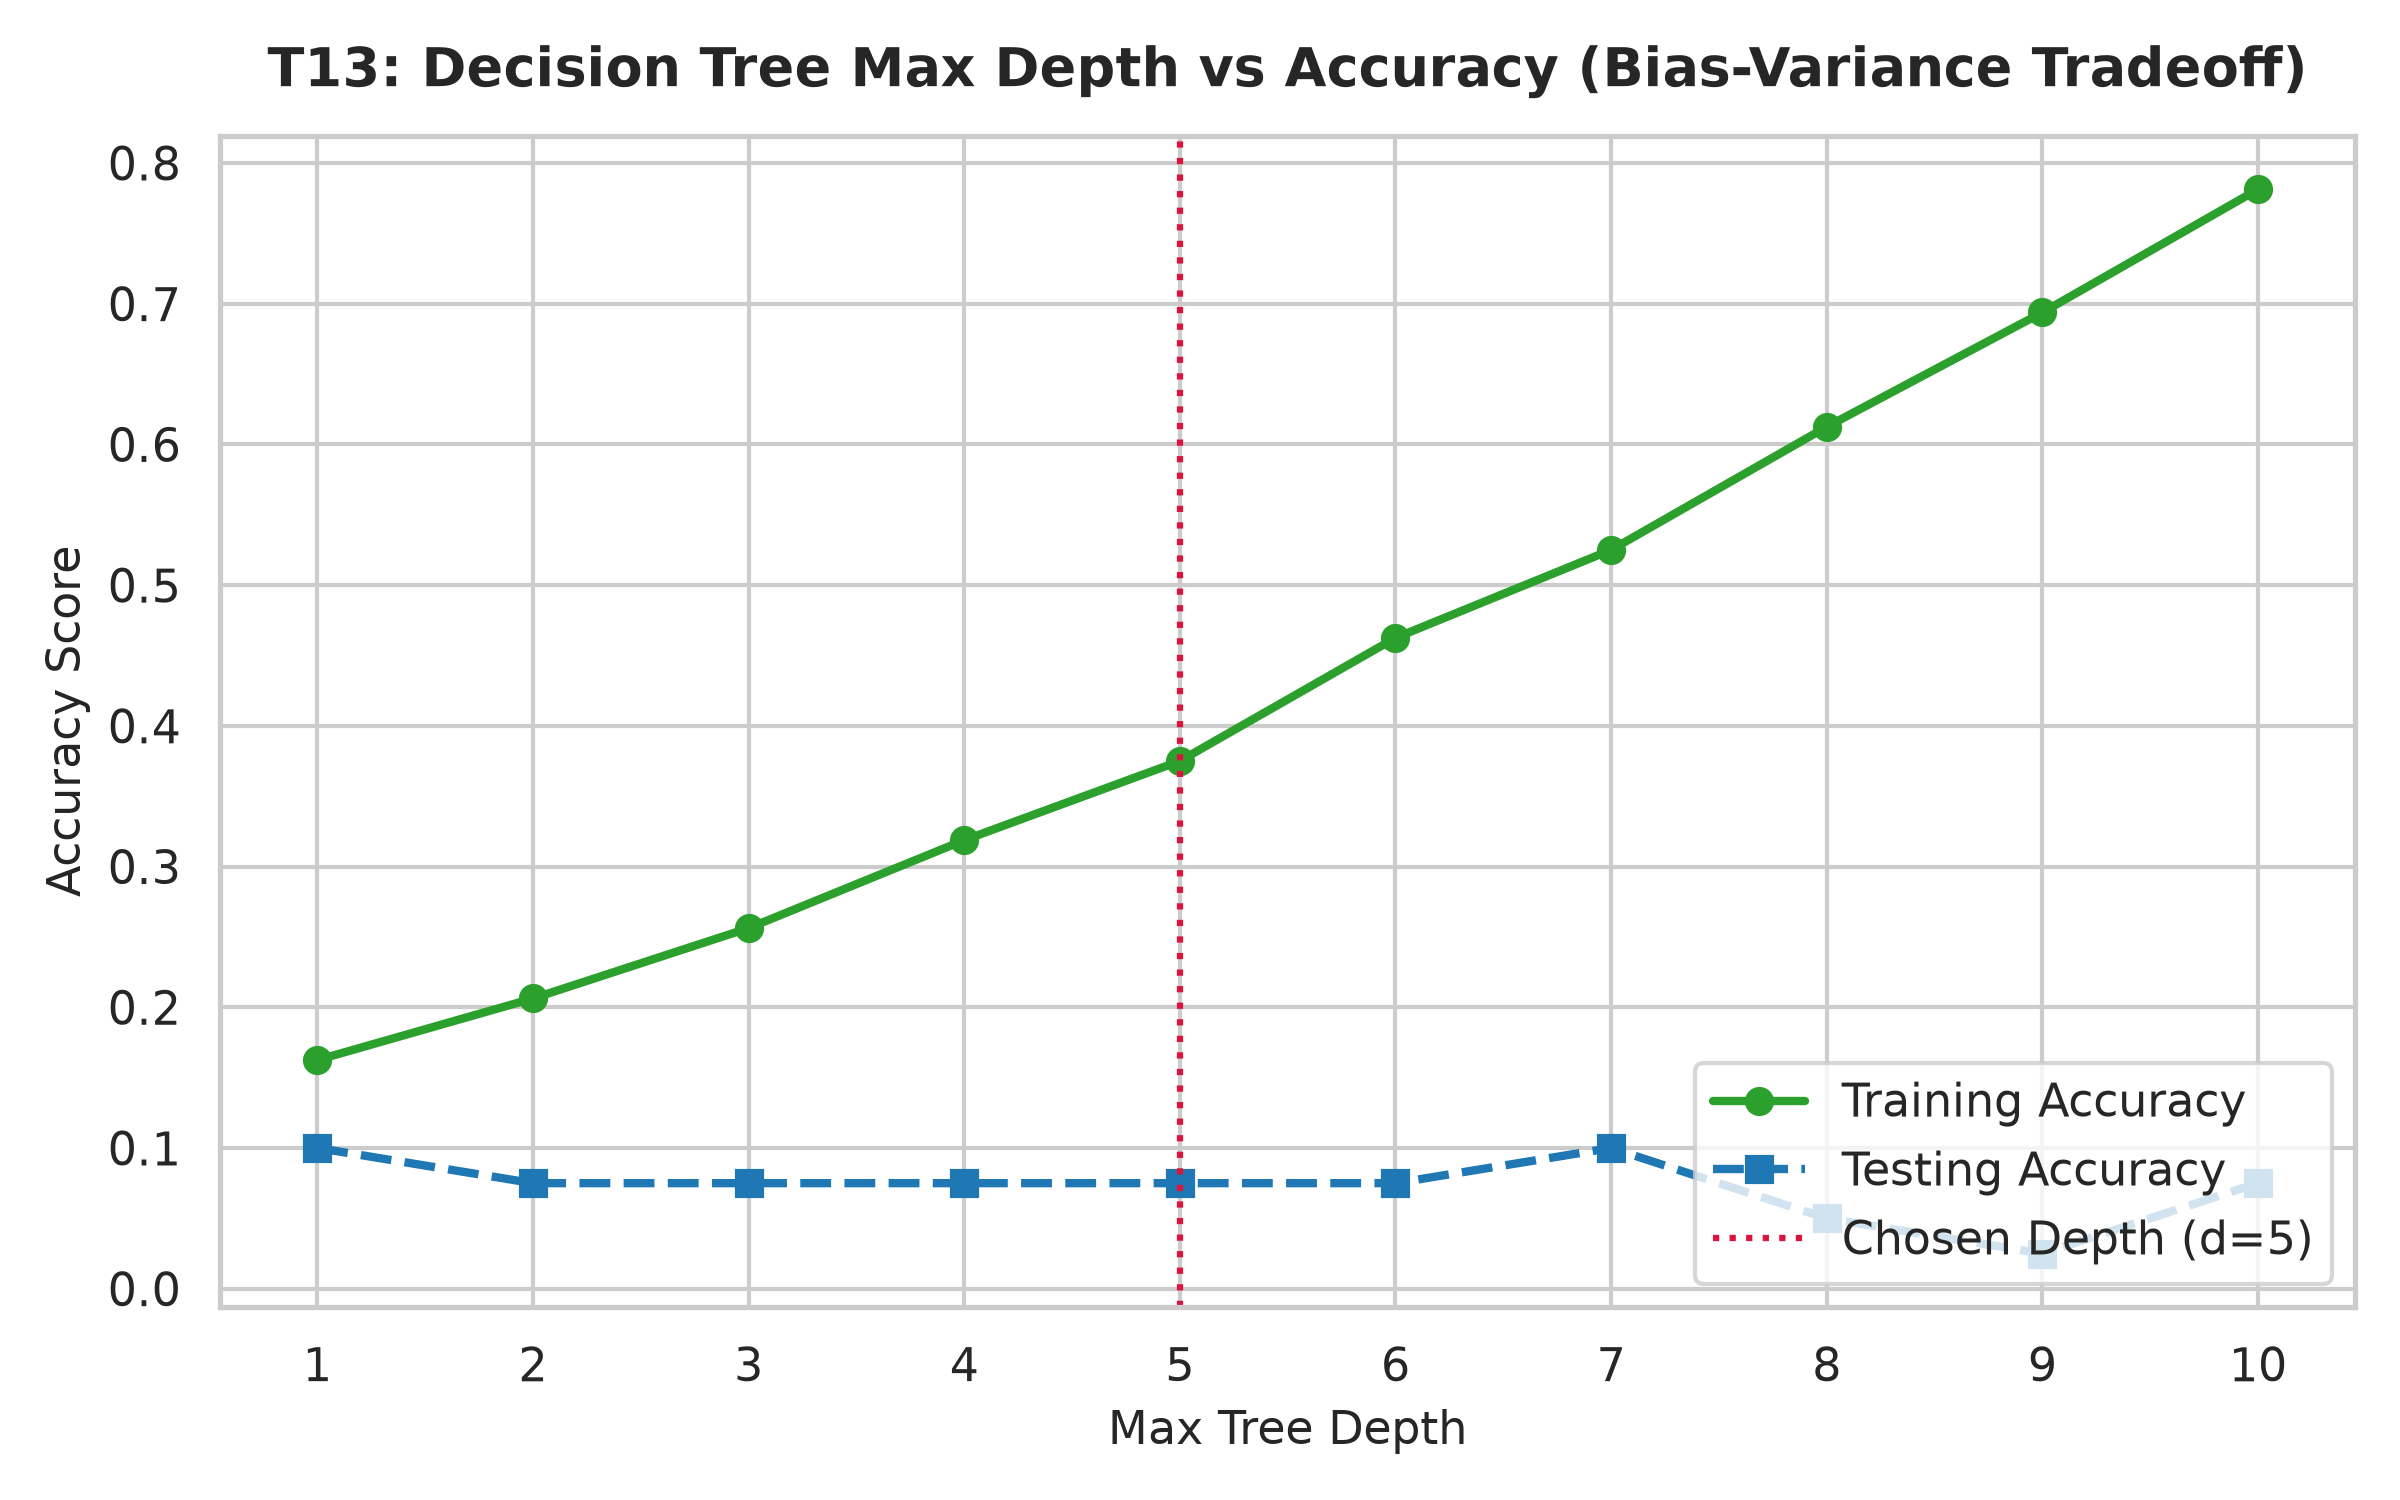

In [3]:
# Step 3: Analyze Tree Depth vs Accuracy (Diagnosing Overfitting)
depths = range(1, 11)
train_scores = []
test_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    dt.fit(X_train, y_train)
    train_scores.append(dt.score(X_train, y_train))
    test_scores.append(dt.score(X_test, y_test))

plt.figure(figsize=(8, 5), dpi=300)
plt.plot(list(depths), train_scores, 'o-', color='#2ca02c', linewidth=2, label="Train Accuracy")
plt.plot(list(depths), test_scores, 's--', color='#1f77b4', linewidth=2, label="Test Accuracy")
plt.title("T13: Decision Tree Max Depth vs Accuracy (Bias-Variance Tradeoff)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Max Tree Depth", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.xticks(list(depths))
plt.axvline(x=5, color='crimson', linestyle=':', label='Chosen Depth (d=5)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [4]:
# Step 4: Fit Optimal Decision Tree (max_depth=5) & Evaluate
dt_model = DecisionTreeClassifier(max_depth=5, criterion='gini', random_state=42)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

train_acc = dt_model.score(X_train, y_train)
test_acc = accuracy_score(y_test, y_pred)
print(f"Decision Tree Train Accuracy: {train_acc:.2%}")
print(f"Decision Tree Test Accuracy:  {test_acc:.2%}\n")
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=classes, zero_division=0))


Decision Tree Train Accuracy: 37.50%
Decision Tree Test Accuracy:  7.50%

=== Classification Report ===
              precision    recall  f1-score   support

   blackgram       0.00      0.00      0.00         4
    chickpea       0.00      0.00      0.00         4
 kidneybeans       0.00      0.00      0.00         3
      lentil       0.00      0.00      0.00         5
       maize       0.00      0.00      0.00         4
   mothbeans       0.25      0.25      0.25         4
    mungbean       0.00      0.00      0.00         5
  pigeonpeas       0.11      0.33      0.17         3
 pomegranate       0.08      0.25      0.12         4
        rice       0.00      0.00      0.00         4

    accuracy                           0.07        40
   macro avg       0.04      0.08      0.05        40
weighted avg       0.04      0.07      0.05        40


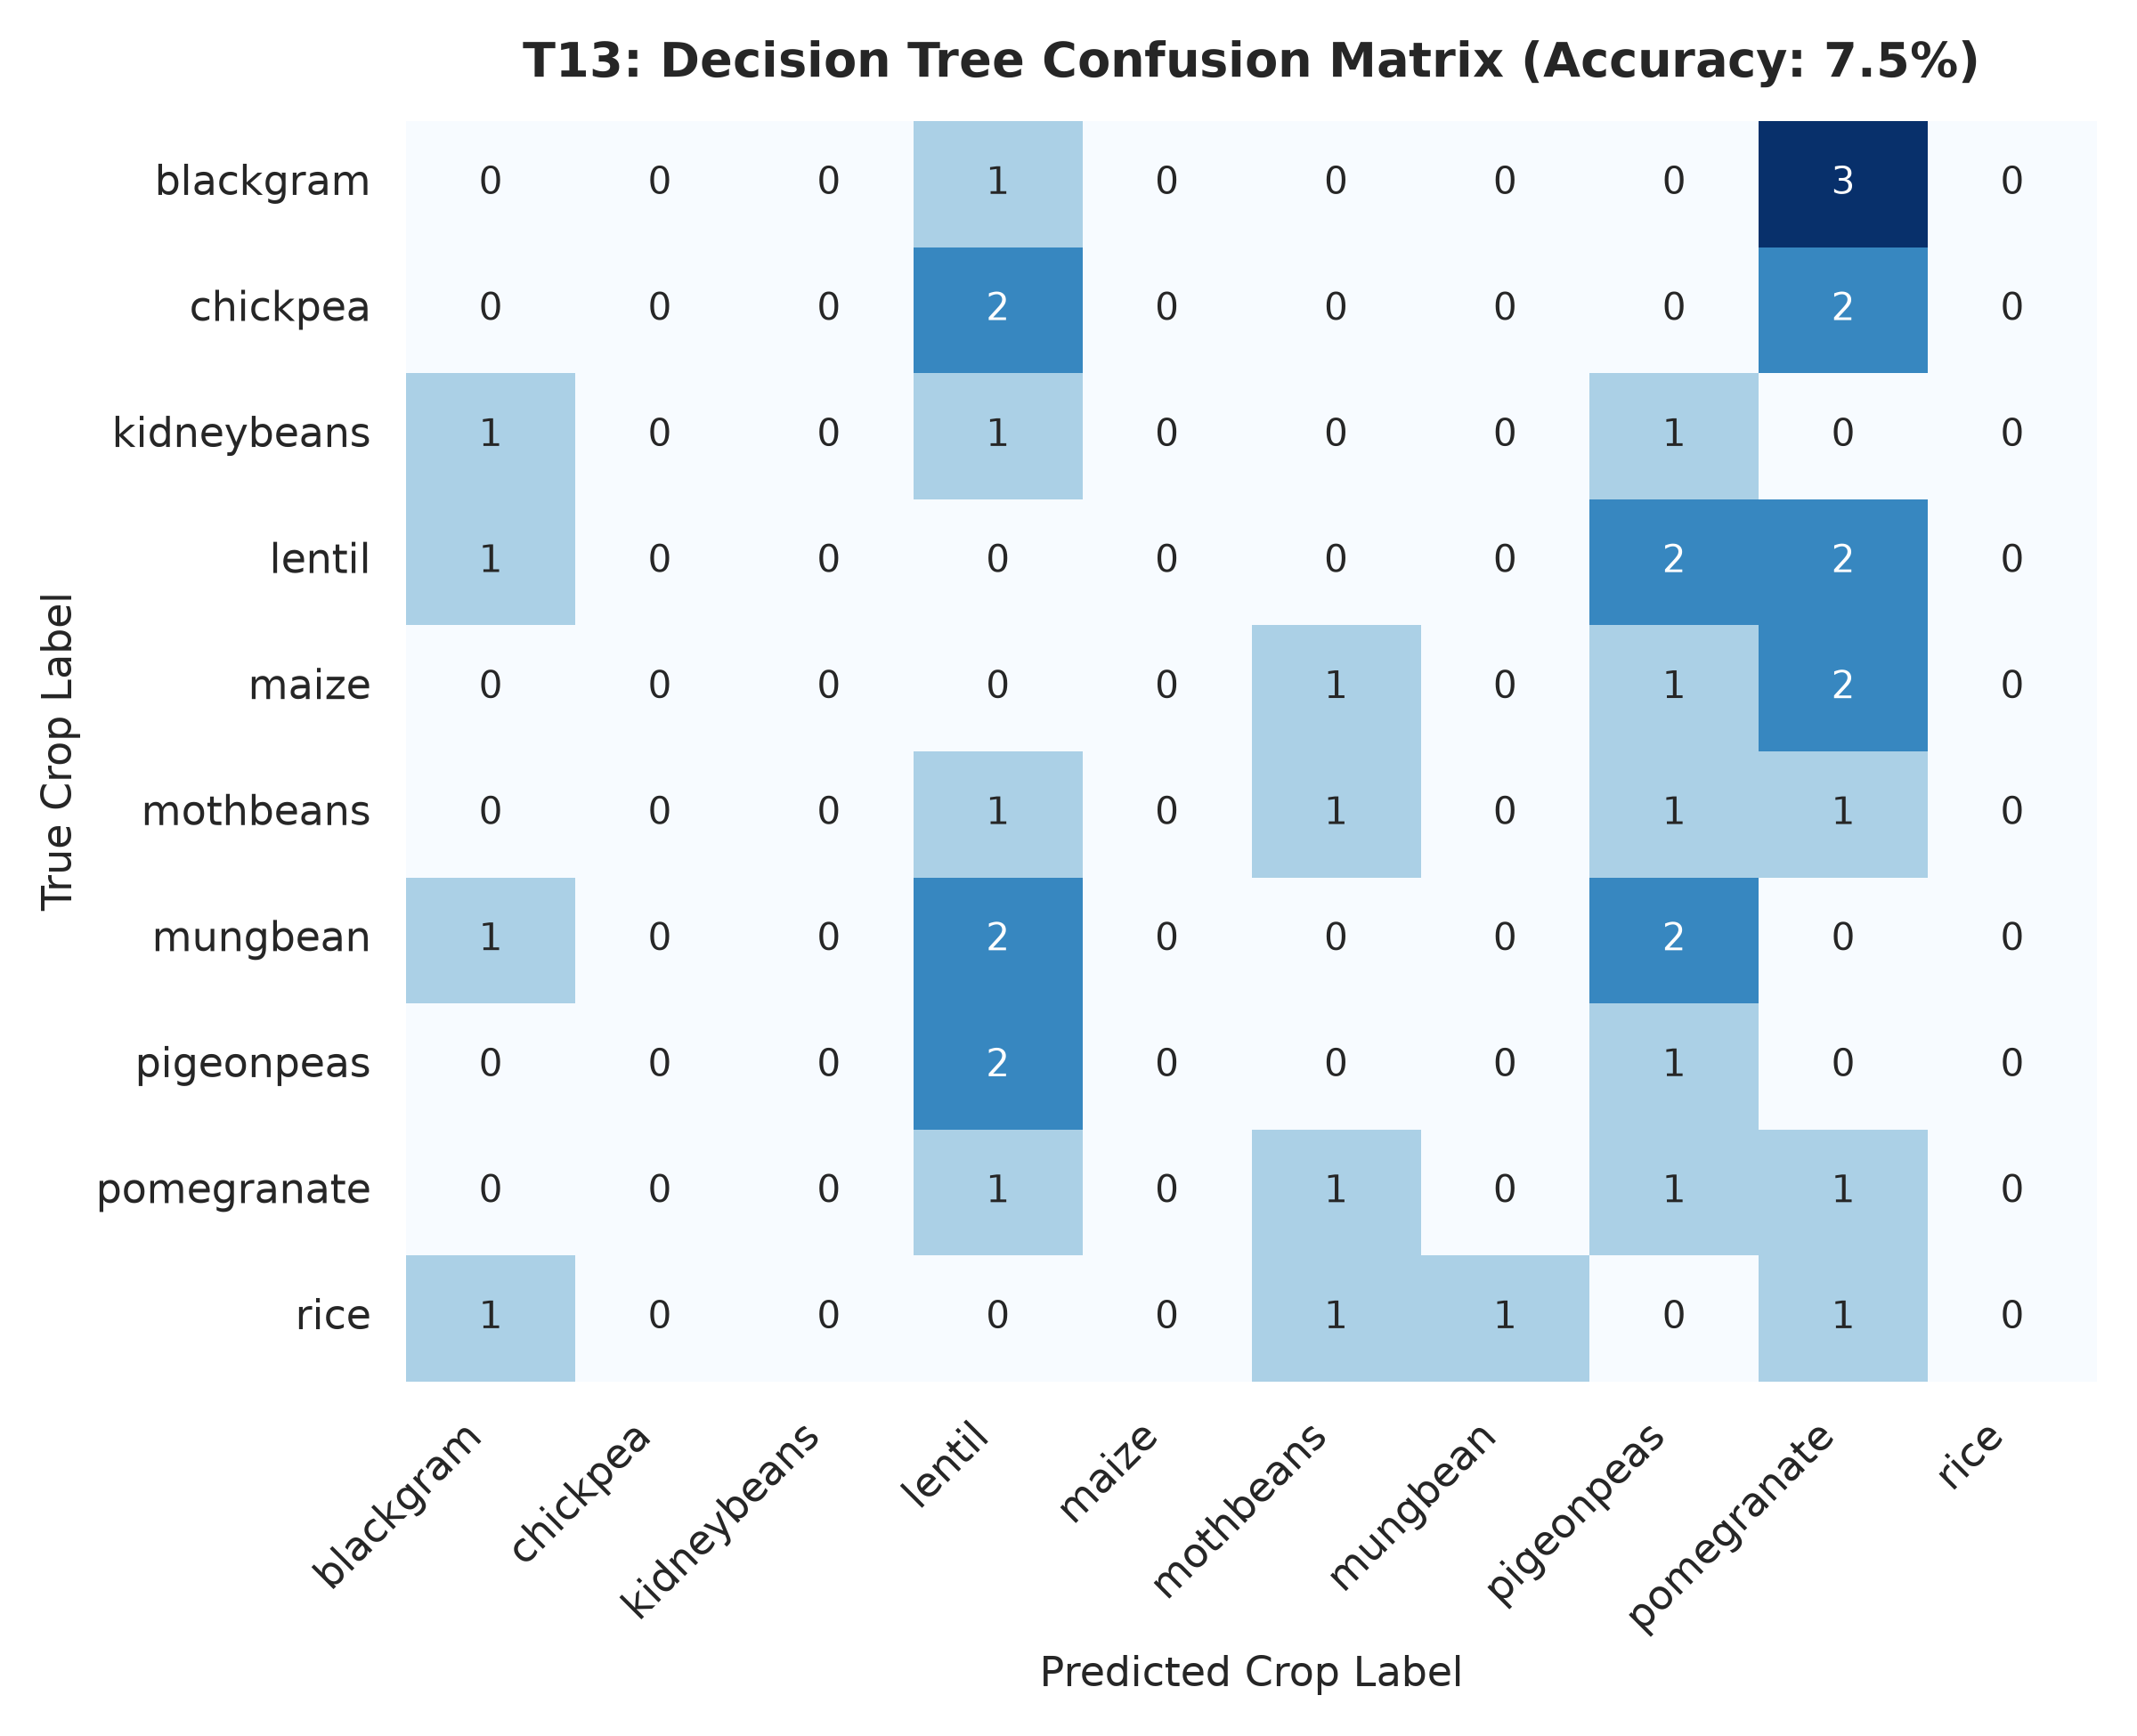

In [5]:
# Step 5: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6.5), dpi=300)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f"T13: Decision Tree Confusion Matrix (Accuracy: {test_acc:.1%})", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Crop Label", fontsize=11)
plt.ylabel("True Crop Label", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


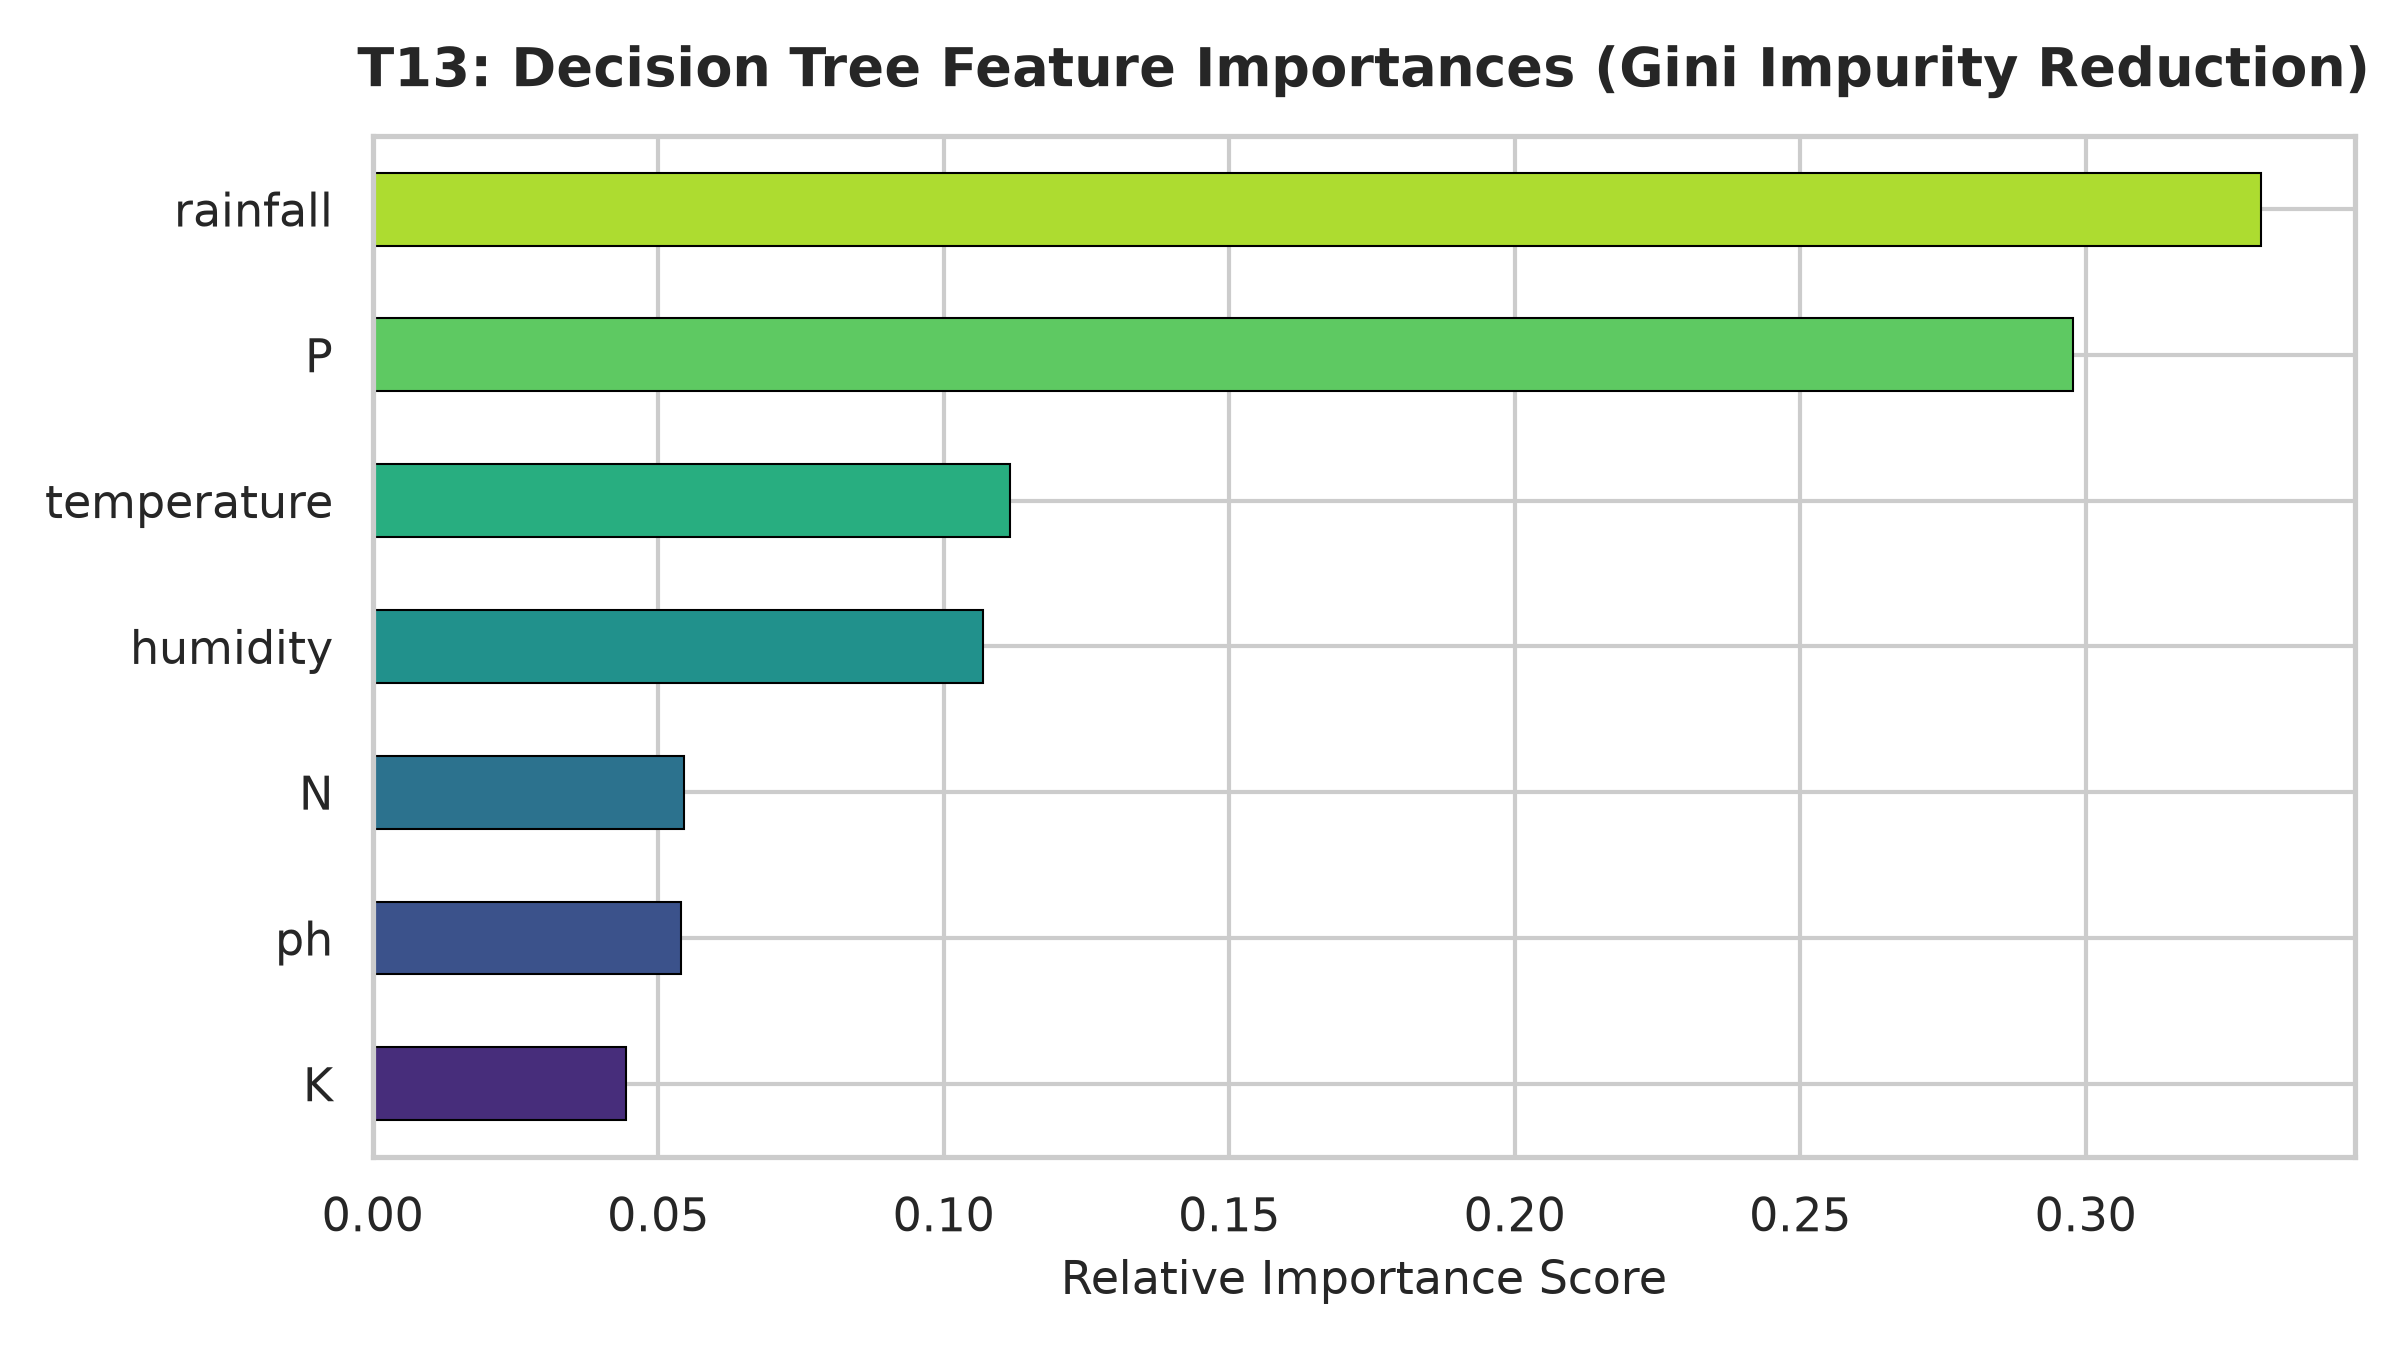

In [6]:
# Step 6: Feature Importances
plt.figure(figsize=(8, 4.5), dpi=300)
dt_fi = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
colors = sns.color_palette("viridis", len(dt_fi))
dt_fi.plot(kind='barh', color=colors, edgecolor='black', linewidth=0.5)
plt.title("T13: Decision Tree Feature Importances (Gini Impurity Reduction)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Relative Importance Score", fontsize=11)
plt.tight_layout()
plt.show()


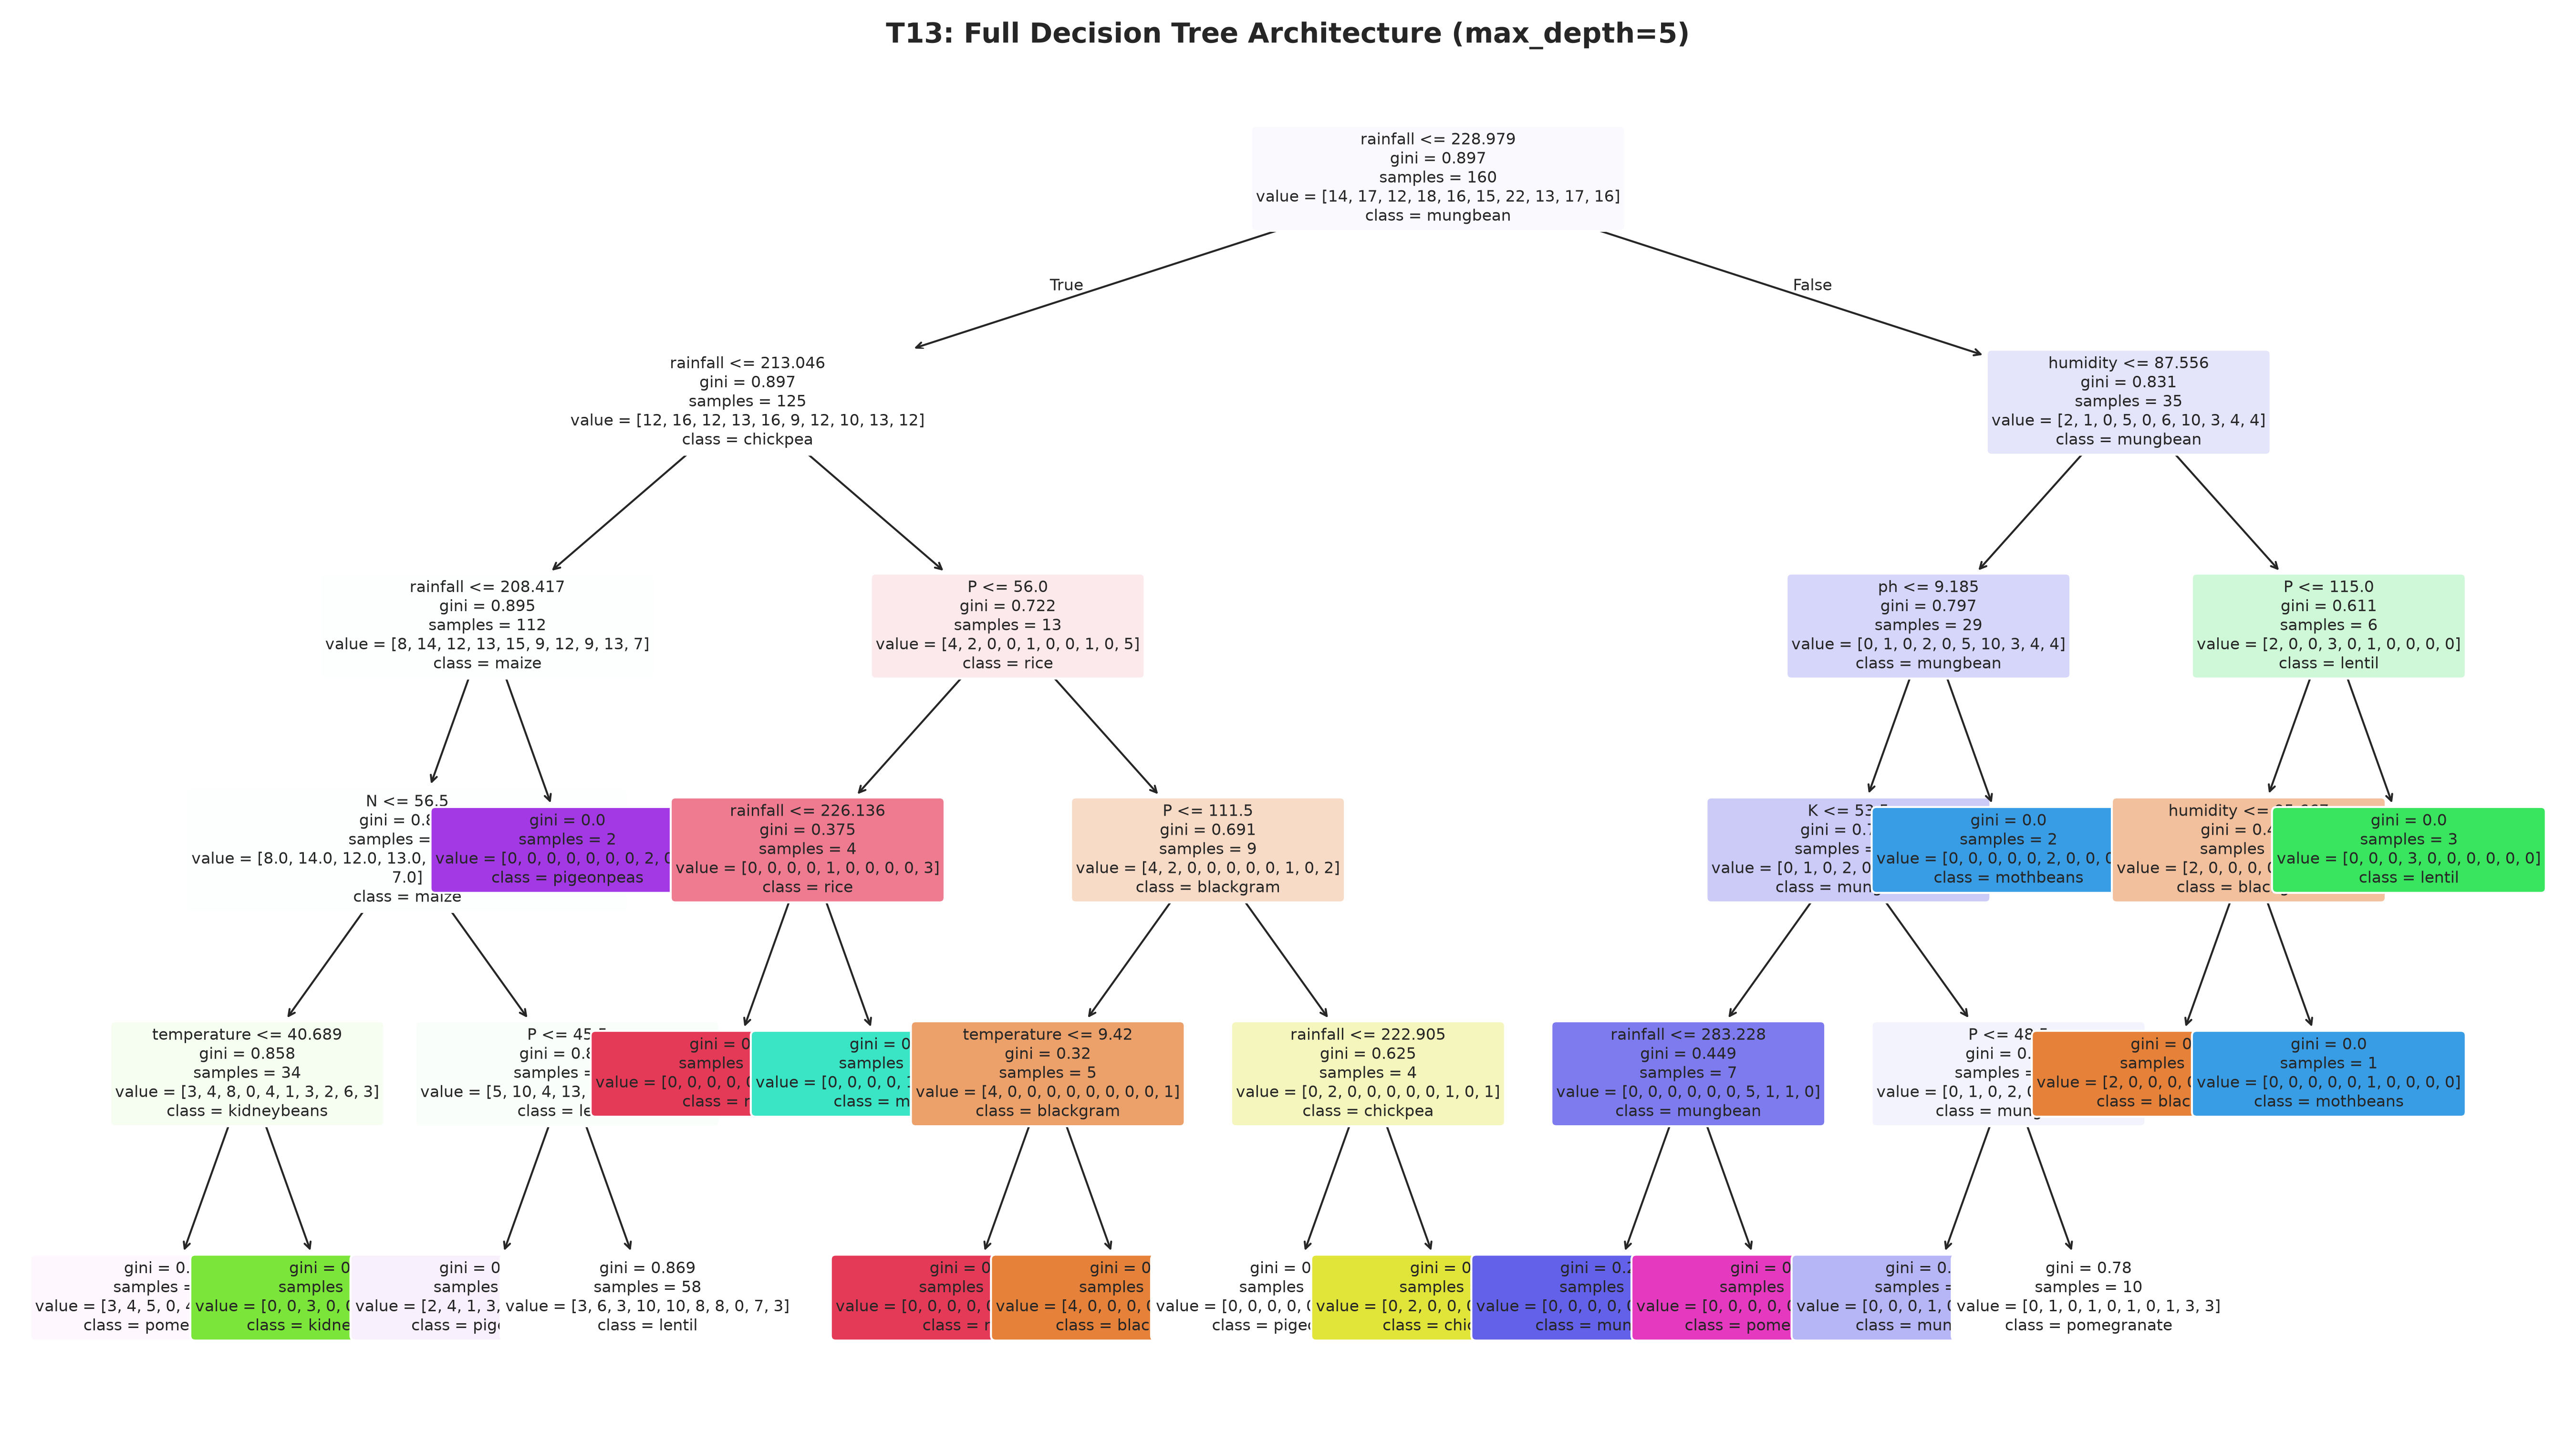

In [7]:
# Step 7: Visualize Full Decision Tree Architecture
plt.figure(figsize=(18, 10), dpi=300)
plot_tree(dt_model, feature_names=feature_cols, class_names=classes, filled=True, rounded=True, fontsize=8)
plt.title("T13: Full Decision Tree Architecture (max_depth=5)", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 🧠 Viva Voce & Conceptual Questions (T13):
1. **Q: What is Gini Impurity and how is it calculated?**
   - **A:** Gini Impurity measures the probability of a randomly chosen element being incorrectly labeled if it were randomly labeled according to the distribution of labels in the node:
   $$I_G(p) = 1 - \sum_{i=1}^{J} p_i^2$$
   A pure node (all samples from 1 class) has $I_G = 0$.
2. **Q: How does Decision Tree pruning prevent overfitting?**
   - **A:** Unconstrained trees grow until every leaf is pure, memorizing training noise (high variance). Pre-pruning limits growth using parameters like `max_depth`, `min_samples_split`, and `min_samples_leaf`. Post-pruning uses Cost-Complexity Pruning (CCP) with parameter $\alpha$ to prune subtrees that don't contribute significantly to accuracy.
3. **Q: How does CART choose the best split at each internal node?**
   - **A:** CART evaluates all possible split thresholds across all features and selects the feature-threshold pair that maximizes the reduction in Gini Impurity:
   $$\Delta I_G = I_{G,\text{parent}} - \left(\frac{N_L}{N} I_{G,\text{left}} + \frac{N_R}{N} I_{G,\text{right}}\right)$$




---
# 🚀 CHAPTER: T14: RANDOM FOREST ALGORITHM
---


In [1]:
# Step 1: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
print("✅ Random Forest libraries loaded.")


✅ Random Forest libraries loaded.


In [2]:
# Step 2: Load Data and Train-Test Split (80/20)
df = pd.read_csv("data/Crop_recommendation.csv")
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[feature_cols].values
le = LabelEncoder()
y = le.fit_transform(df['label'].values)
classes = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Data split: {X_train.shape[0]} train, {X_test.shape[0]} test samples.")


Data split: 160 train, 40 test samples.


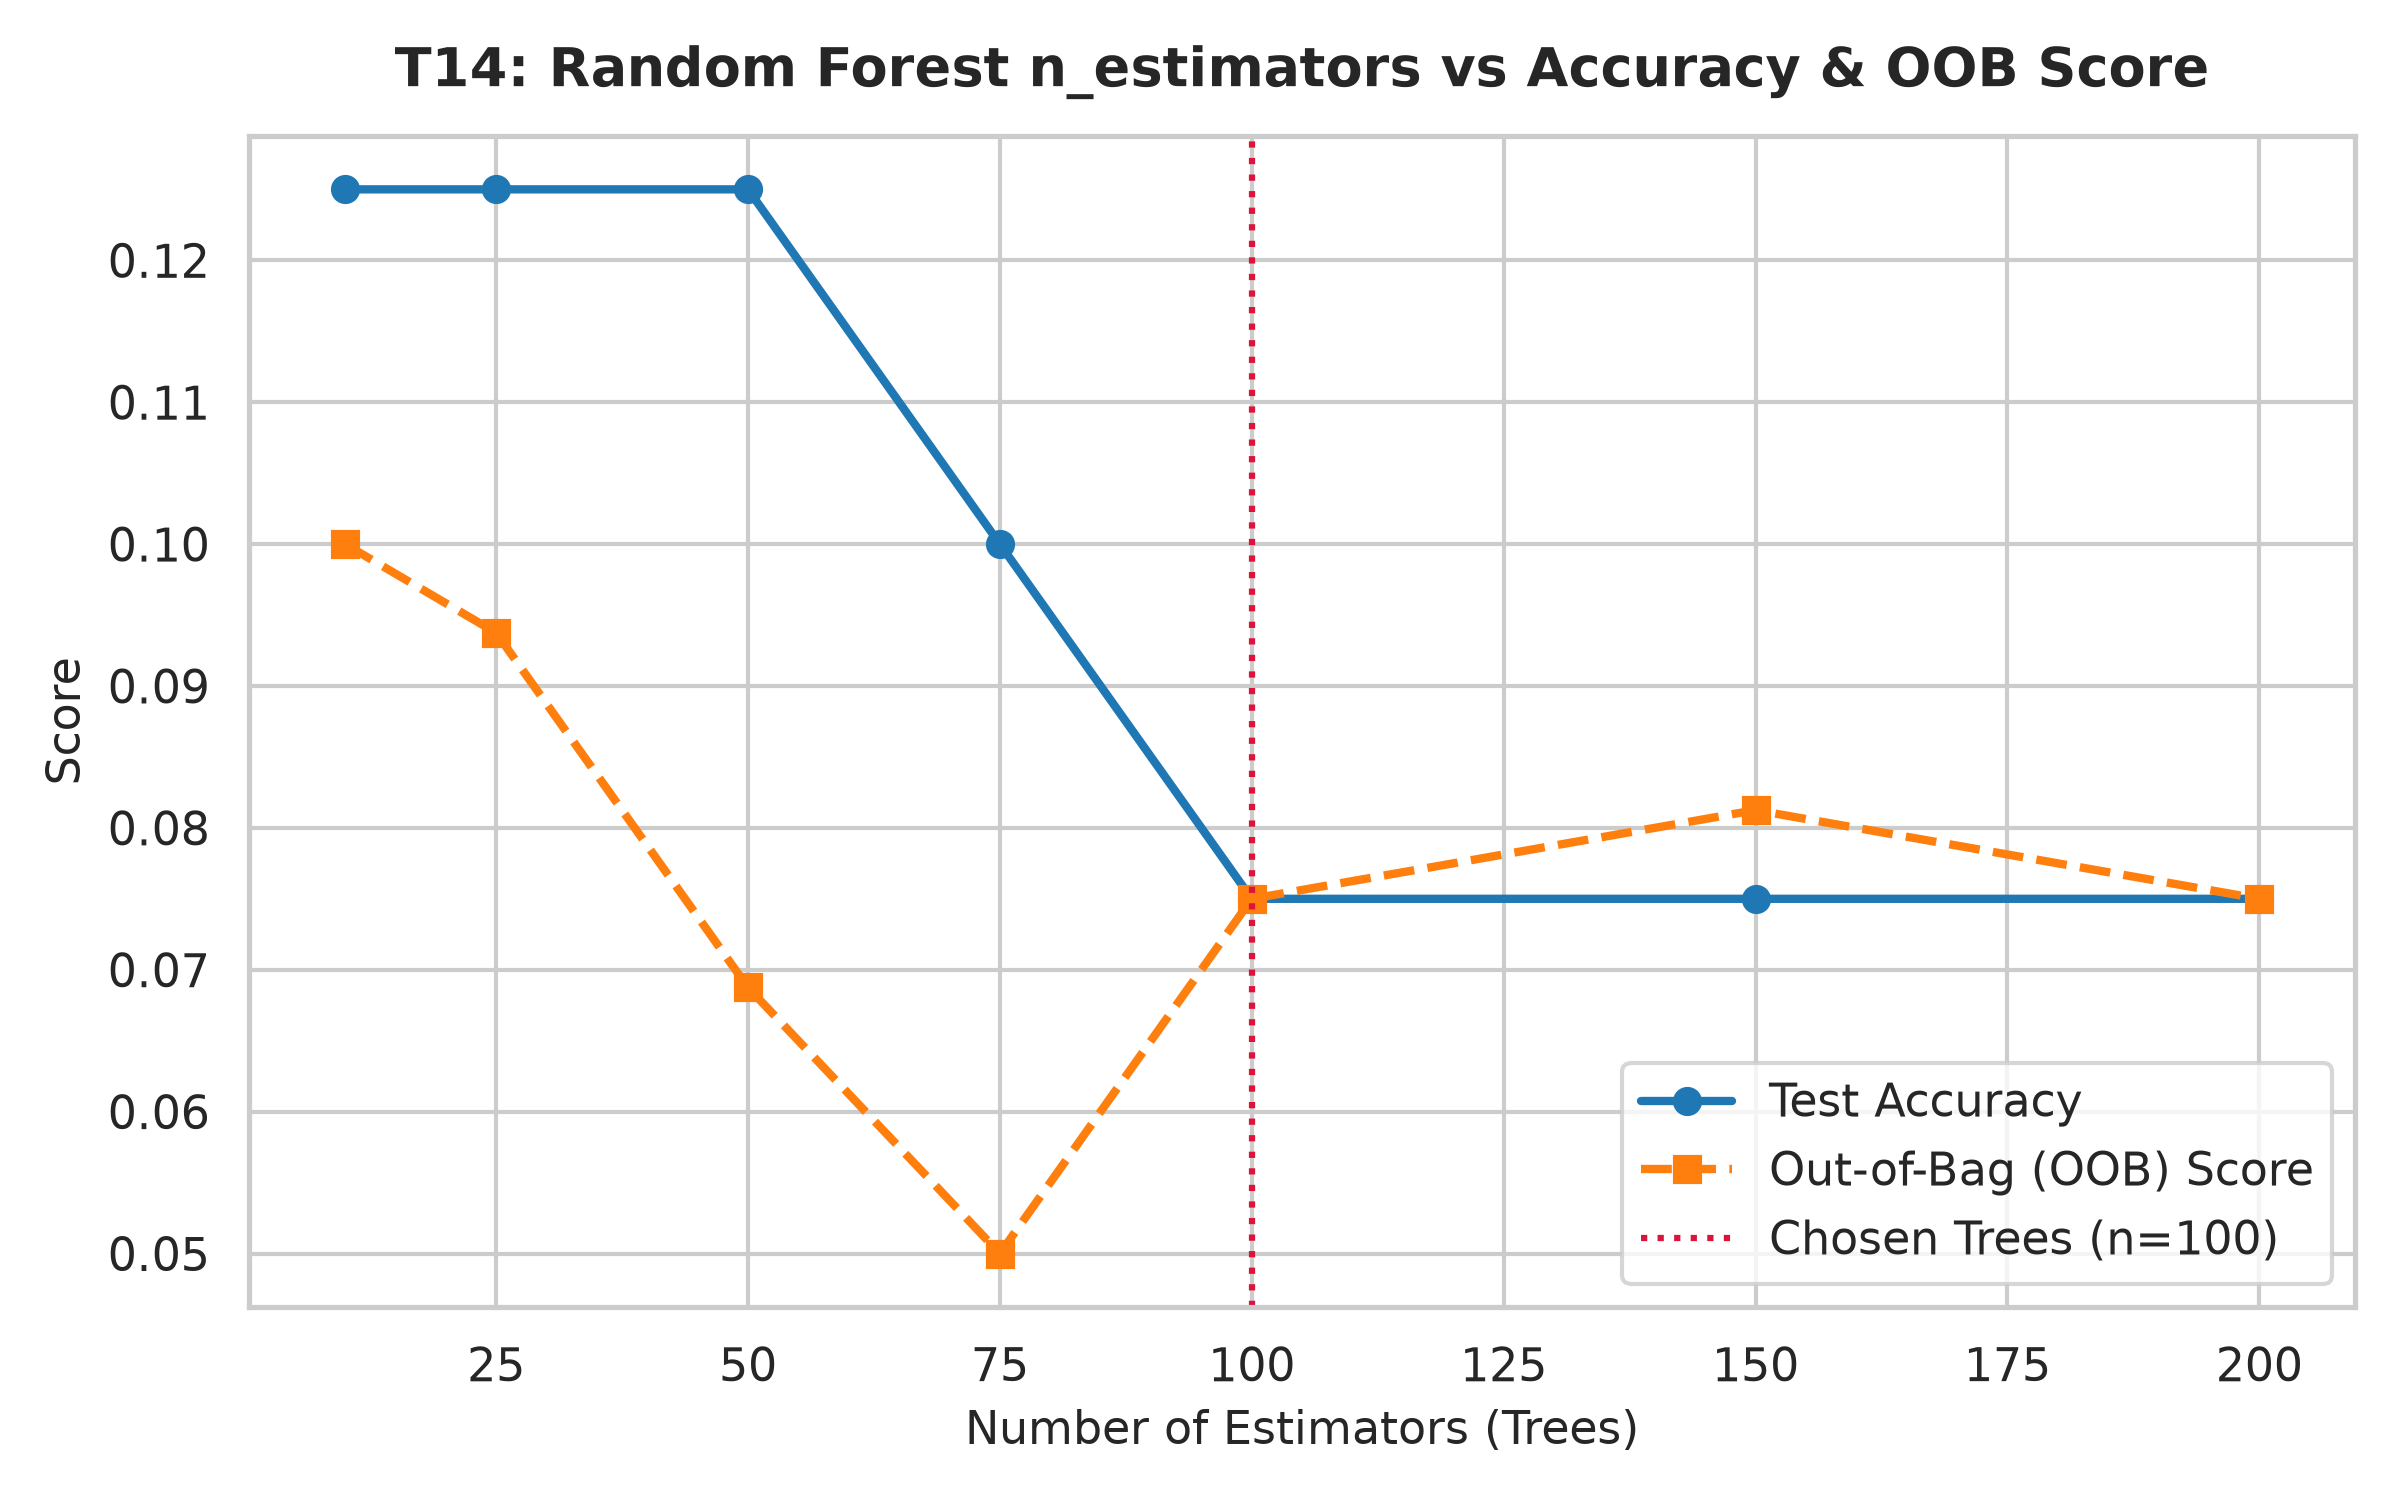

In [3]:
# Step 3: Analyze Number of Estimators vs Accuracy & OOB Score
n_est_range = [10, 25, 50, 75, 100, 150, 200]
oob_scores = []
test_scores = []

for n in n_est_range:
    rf_temp = RandomForestClassifier(n_estimators=n, max_depth=8, oob_score=True, random_state=42)
    rf_temp.fit(X_train, y_train)
    oob_scores.append(rf_temp.oob_score_)
    test_scores.append(rf_temp.score(X_test, y_test))

plt.figure(figsize=(8, 5), dpi=300)
plt.plot(n_est_range, test_scores, 'o-', color='#1f77b4', linewidth=2, label="Test Accuracy")
plt.plot(n_est_range, oob_scores, 's--', color='#ff7f0e', linewidth=2, label="Out-of-Bag (OOB) Score")
plt.title("T14: Random Forest n_estimators vs Accuracy & OOB Score", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Number of Estimators (Trees)", fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.axvline(x=100, color='crimson', linestyle=':', label='Chosen Trees (n=100)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [4]:
# Step 4: Fit Final Random Forest (n=100) & Evaluate
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, oob_score=True, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

train_acc = rf_model.score(X_train, y_train)
test_acc = accuracy_score(y_test, y_pred_rf)
oob_acc = rf_model.oob_score_

print(f"Random Forest Train Accuracy: {train_acc:.2%}")
print(f"Random Forest Test Accuracy:  {test_acc:.2%}")
print(f"Random Forest OOB Score:      {oob_acc:.2%}\n")
print("=== Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=classes, zero_division=0))


Random Forest Train Accuracy: 100.00%
Random Forest Test Accuracy:  7.50%
Random Forest OOB Score:      7.50%

=== Classification Report ===
              precision    recall  f1-score   support

   blackgram       0.00      0.00      0.00         4
    chickpea       0.00      0.00      0.00         4
 kidneybeans       0.00      0.00      0.00         3
      lentil       0.17      0.20      0.18         5
       maize       0.00      0.00      0.00         4
   mothbeans       0.00      0.00      0.00         4
    mungbean       0.08      0.20      0.12         5
  pigeonpeas       0.00      0.00      0.00         3
 pomegranate       0.00      0.00      0.00         4
        rice       0.25      0.25      0.25         4

    accuracy                           0.07        40
   macro avg       0.05      0.07      0.05        40
weighted avg       0.06      0.07      0.06        40


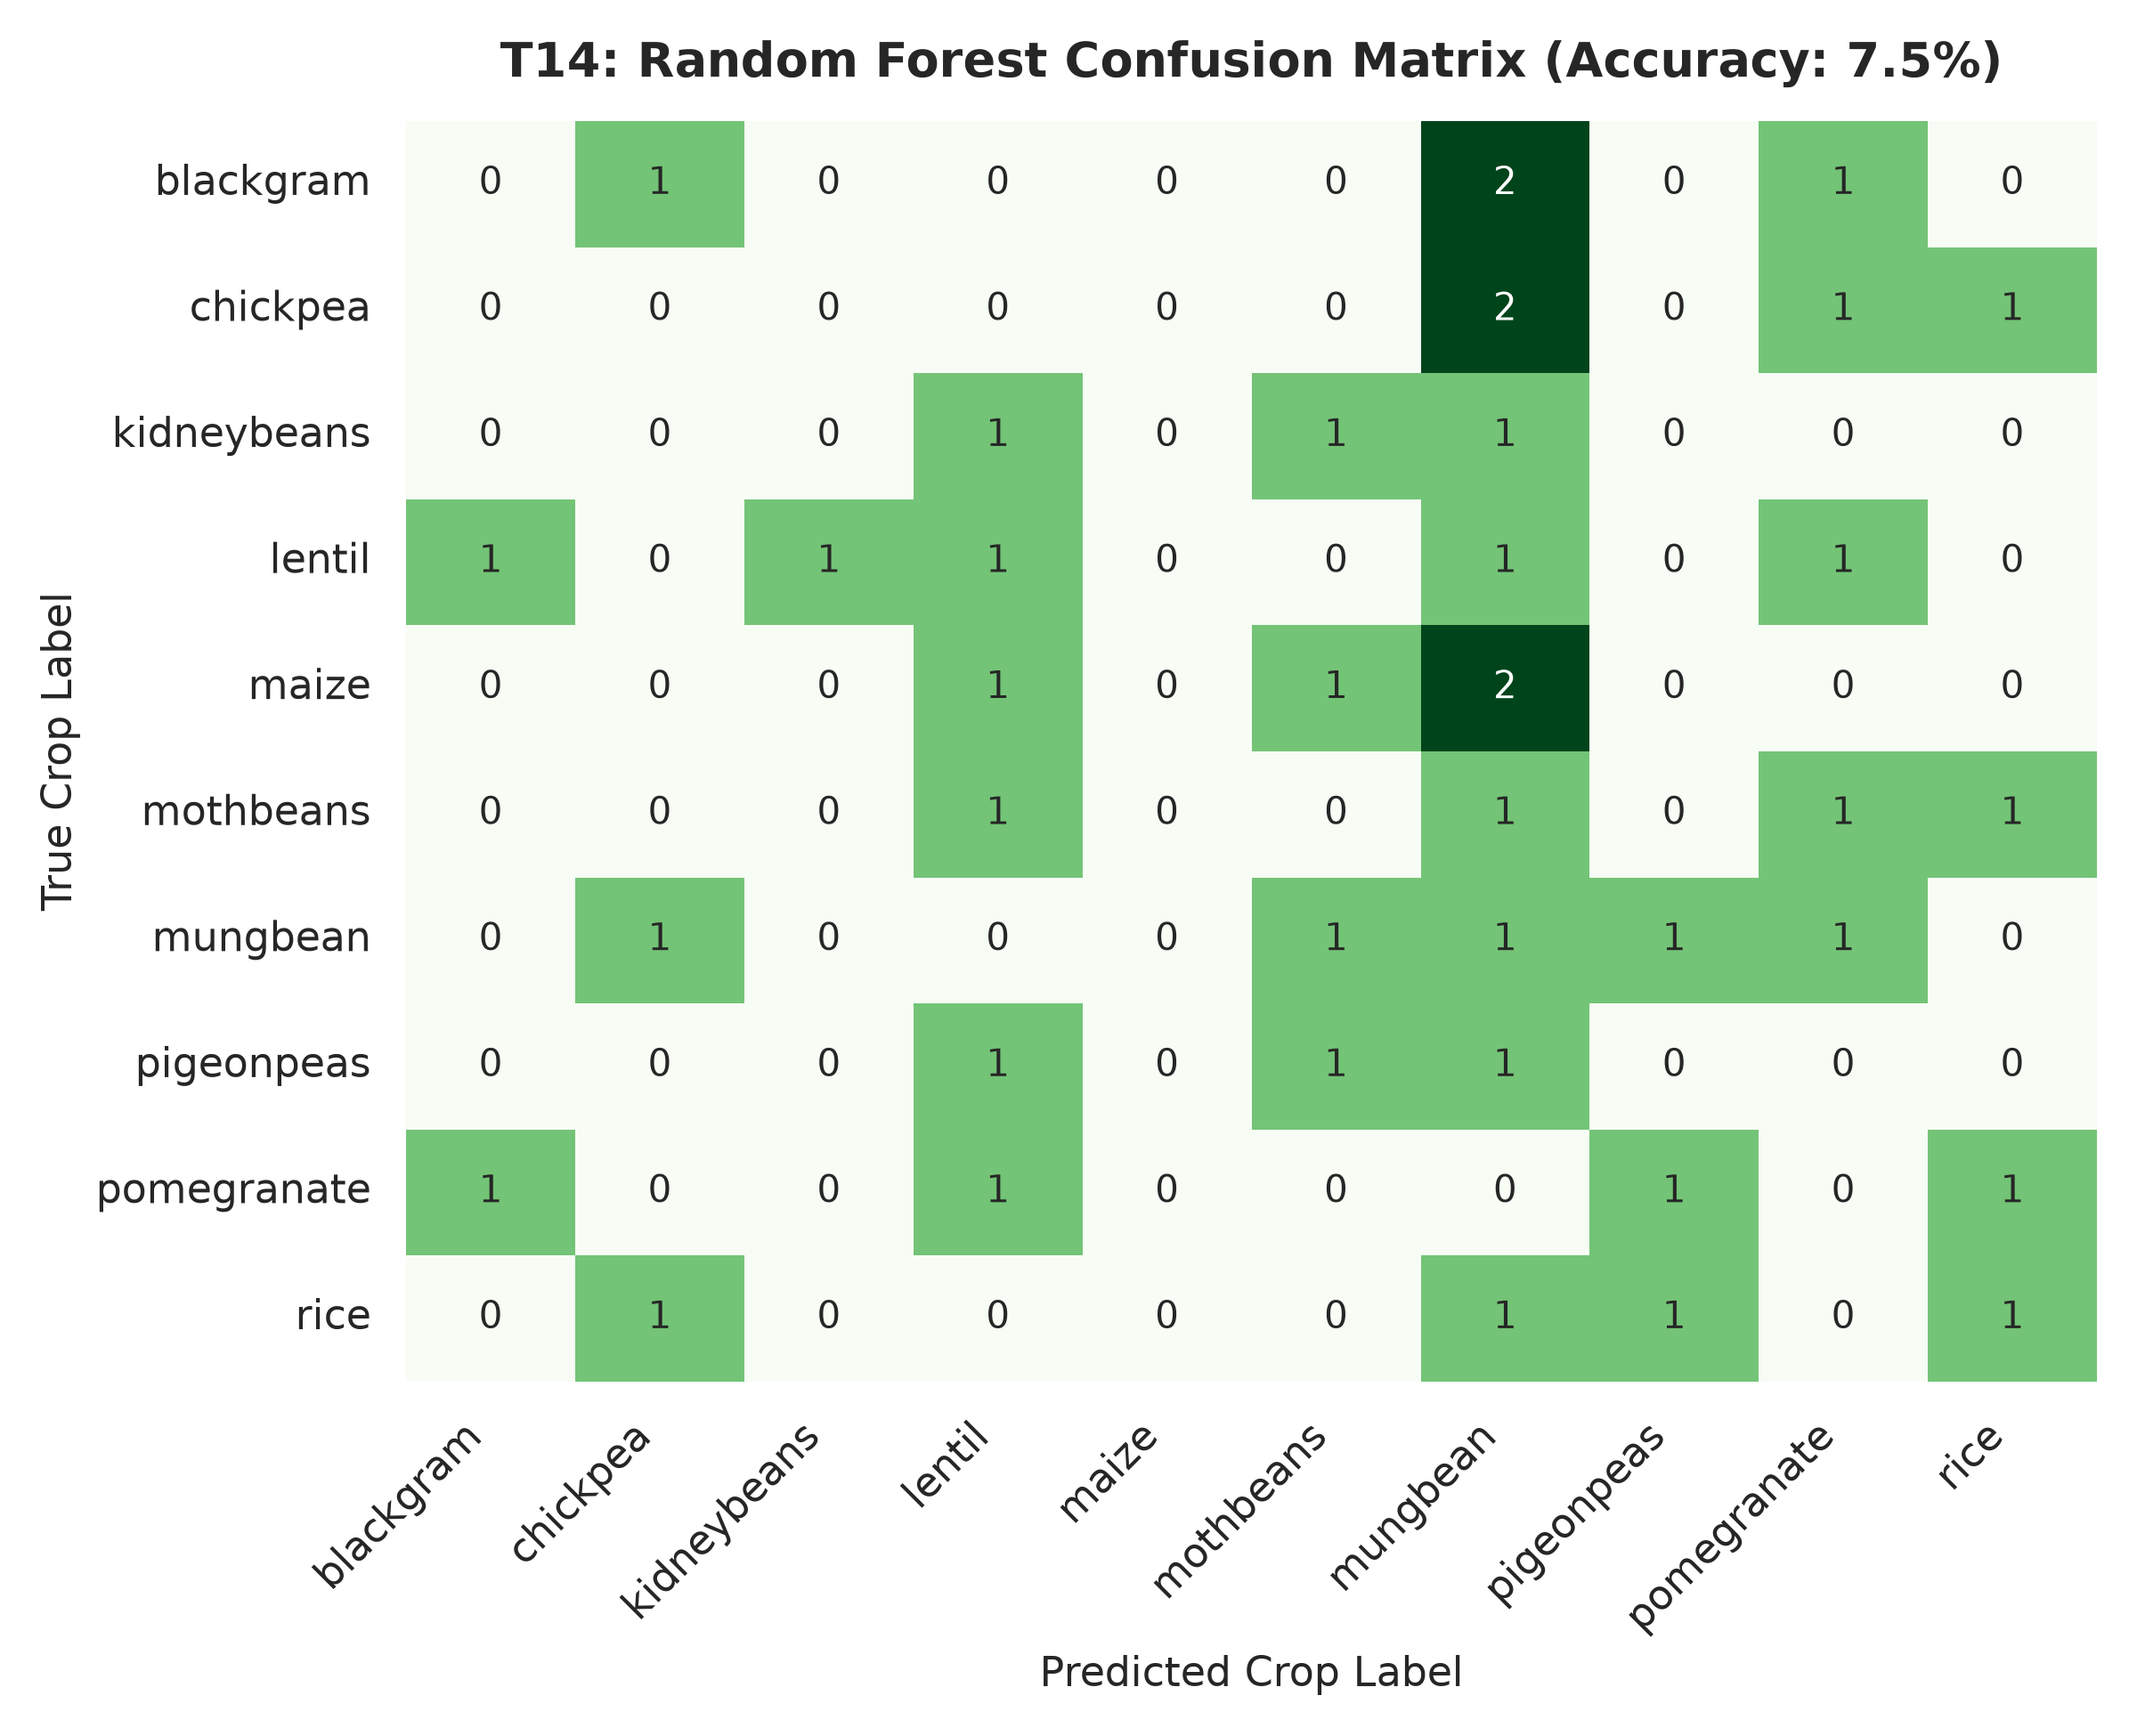

In [5]:
# Step 5: Confusion Matrix Heatmap
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6.5), dpi=300)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f"T14: Random Forest Confusion Matrix (Accuracy: {test_acc:.1%})", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Crop Label", fontsize=11)
plt.ylabel("True Crop Label", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


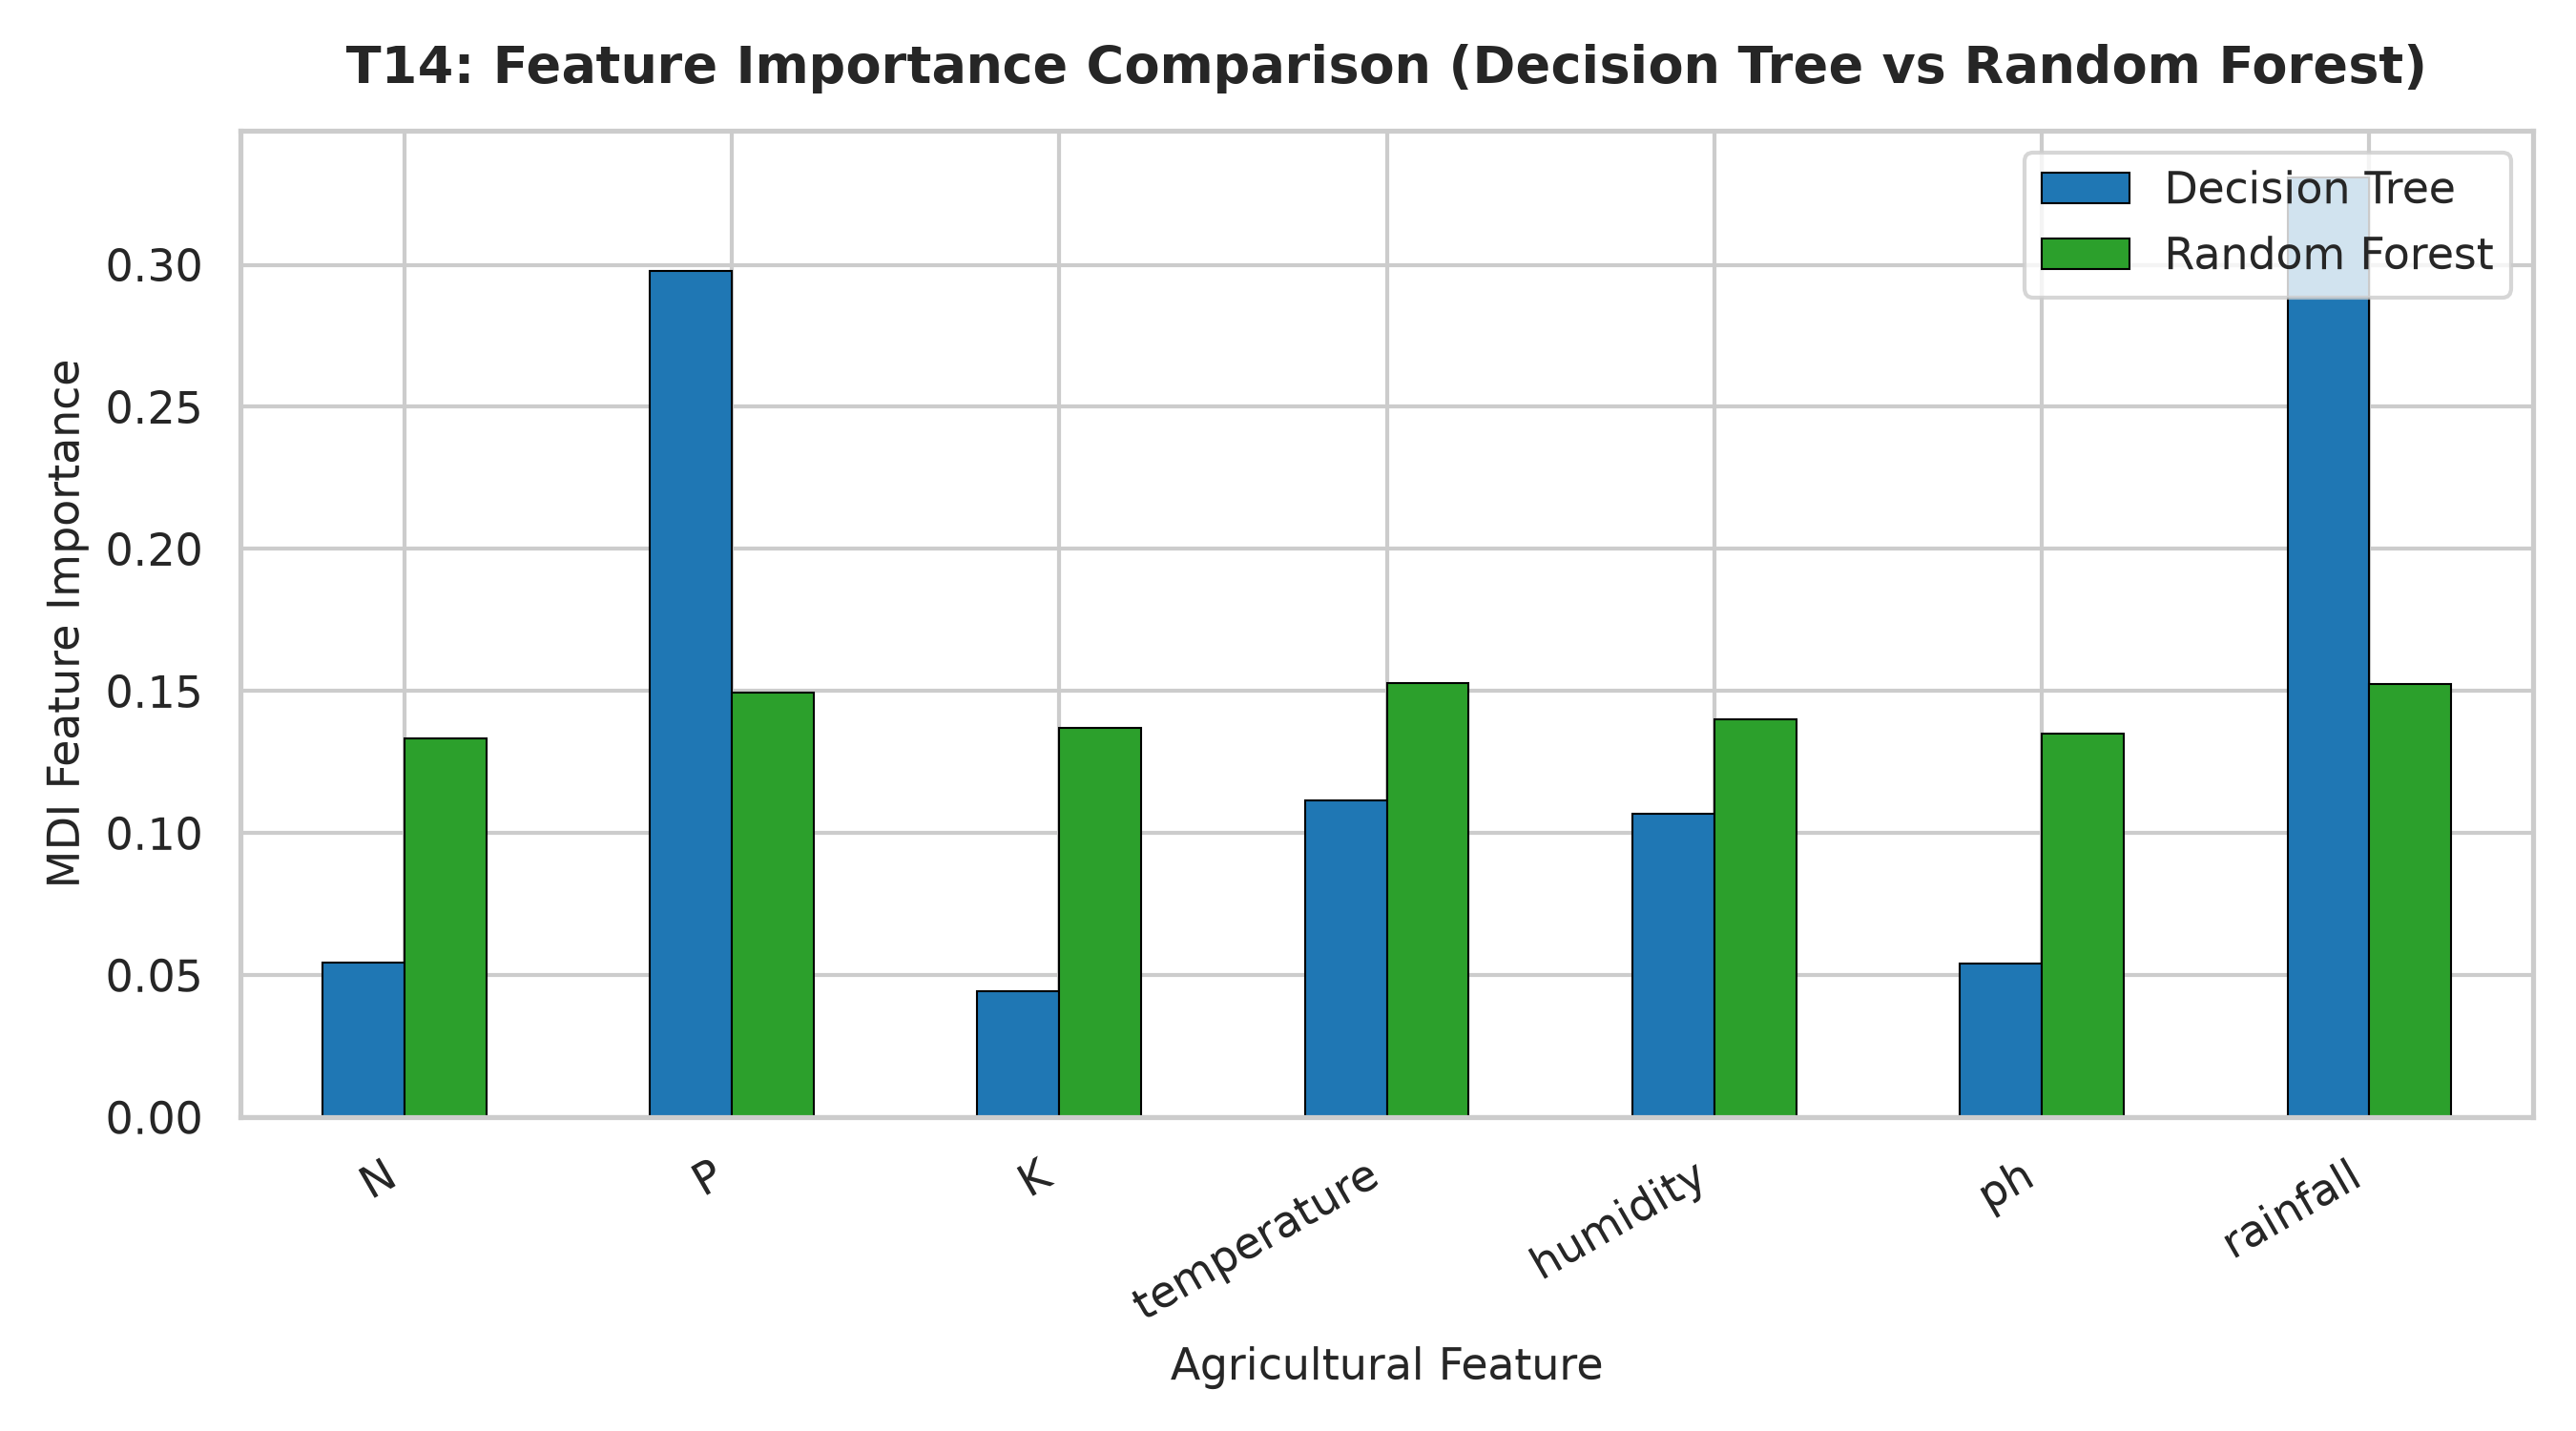

In [6]:
# Step 6: Feature Importance Comparison (Decision Tree vs Random Forest)
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

df_fi = pd.DataFrame({
    'Decision Tree': dt_model.feature_importances_,
    'Random Forest': rf_model.feature_importances_
}, index=feature_cols)

plt.figure(figsize=(9, 5), dpi=300)
df_fi.plot(kind='bar', figsize=(9, 5), color=['#1f77b4', '#2ca02c'], edgecolor='black', linewidth=0.5)
plt.title("T14: Feature Importance Comparison (Decision Tree vs Random Forest)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Agricultural Feature", fontsize=11)
plt.ylabel("MDI Feature Importance", fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### 🧠 Viva Voce & Conceptual Questions (T14):
1. **Q: What is Bootstrap Aggregating (Bagging) and how does it reduce variance?**
   - **A:** Bagging samples $N$ observations with replacement from the training set $B$ times to train $B$ independent base trees. Averaging the predictions of uncorrelated trees reduces variance by a factor of approximately $1/B$ without increasing bias.
2. **Q: What is the purpose of the Random Subspace Method (feature sampling)?**
   - **A:** If one or two features are overwhelmingly dominant, every single bagged tree will choose them at the root, making the trees highly correlated. By sampling a random subset of features (typically $\sqrt{p}$) at each split, Random Forest forces trees to explore different feature subspaces, decorrelating the trees.
3. **Q: What is the Out-Of-Bag (OOB) error?**
   - **A:** Because bootstrap sampling draws with replacement, each bootstrap sample contains only about $1 - 1/e \approx 63.2\%$ of the original dataset. The remaining $36.8\%$ of samples are 'Out-Of-Bag' for that tree. Evaluating each training point only on trees where it was out-of-bag provides an unbiased estimate of generalization error without requiring a separate validation set.




---
# 🚀 CHAPTER: T15: ARTIFICIAL NEURAL NETWORKS
---


In [1]:
# Step 1: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score

sns.set_theme(style="whitegrid")
print("✅ MLP Neural Network libraries loaded.")


✅ MLP Neural Network libraries loaded.


In [2]:
# Step 2: Load Data, Standardize, and Split
df = pd.read_csv("data/Crop_recommendation.csv")
feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[feature_cols].values
le = LabelEncoder()
y = le.fit_transform(df['label'].values)
classes = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Crucial: Feature Scaling for Gradient Descent
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(f"Features scaled for neural network: {X_train_s.shape}")


Features scaled for neural network: (160, 7)


In [3]:
# Step 3: Train MLPClassifier Architecture (7 -> 64 -> 32 -> 10)
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
mlp.fit(X_train_s, y_train)
print(f"Optimization finished in {len(mlp.loss_curve_)} epochs.")
print(f"Final Cross-Entropy Loss: {mlp.loss_curve_[-1]:.4f}")


Optimization finished in 500 epochs.
Final Cross-Entropy Loss: 0.0666


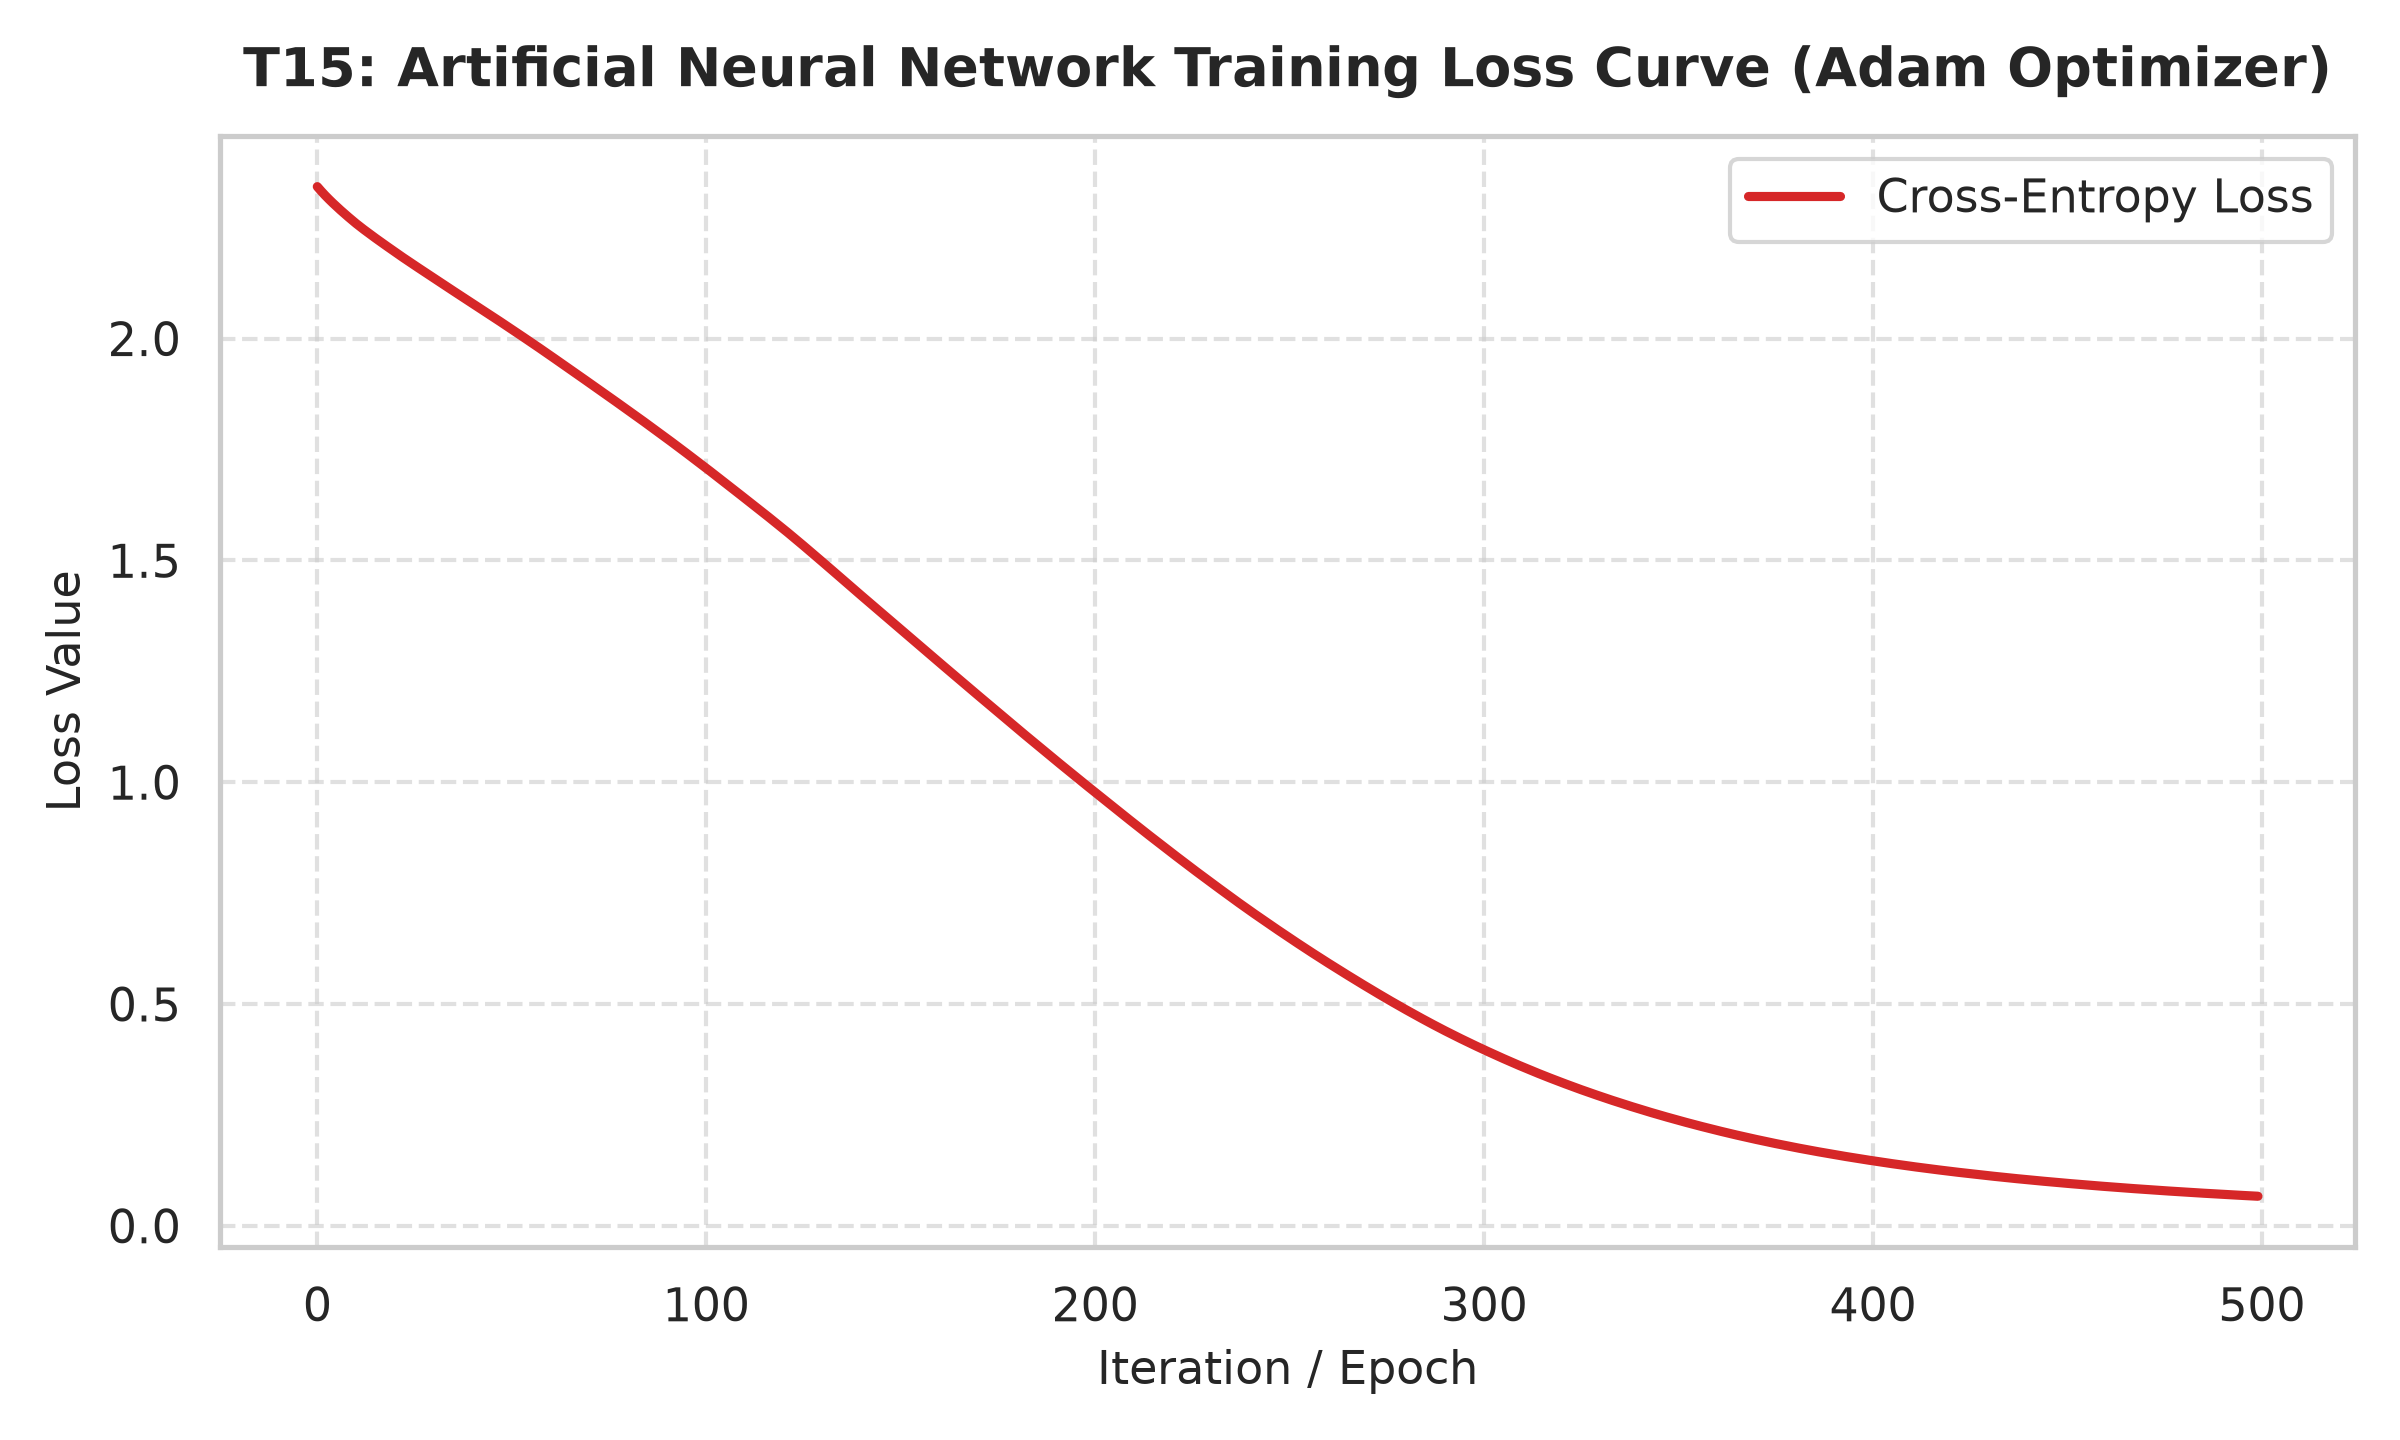

In [4]:
# Step 4: Plot Training Loss Convergence Curve
plt.figure(figsize=(8, 4.8), dpi=300)
plt.plot(mlp.loss_curve_, color='#d62728', linewidth=2.2, label="Cross-Entropy Loss")
plt.title("T15: Artificial Neural Network Training Loss Curve (Adam Optimizer)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Iteration / Epoch", fontsize=11)
plt.ylabel("Loss Value", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


MLP Train Accuracy: 100.00%
MLP Test Accuracy:  12.50%

=== Classification Report ===
              precision    recall  f1-score   support

   blackgram       0.00      0.00      0.00         4
    chickpea       0.40      0.50      0.44         4
 kidneybeans       0.00      0.00      0.00         3
      lentil       0.25      0.20      0.22         5
       maize       0.00      0.00      0.00         4
   mothbeans       0.33      0.25      0.29         4
    mungbean       0.00      0.00      0.00         5
  pigeonpeas       0.50      0.33      0.40         3
 pomegranate       0.00      0.00      0.00         4
        rice       0.00      0.00      0.00         4

    accuracy                           0.12        40
   macro avg       0.15      0.13      0.14        40
weighted avg       0.14      0.12      0.13        40


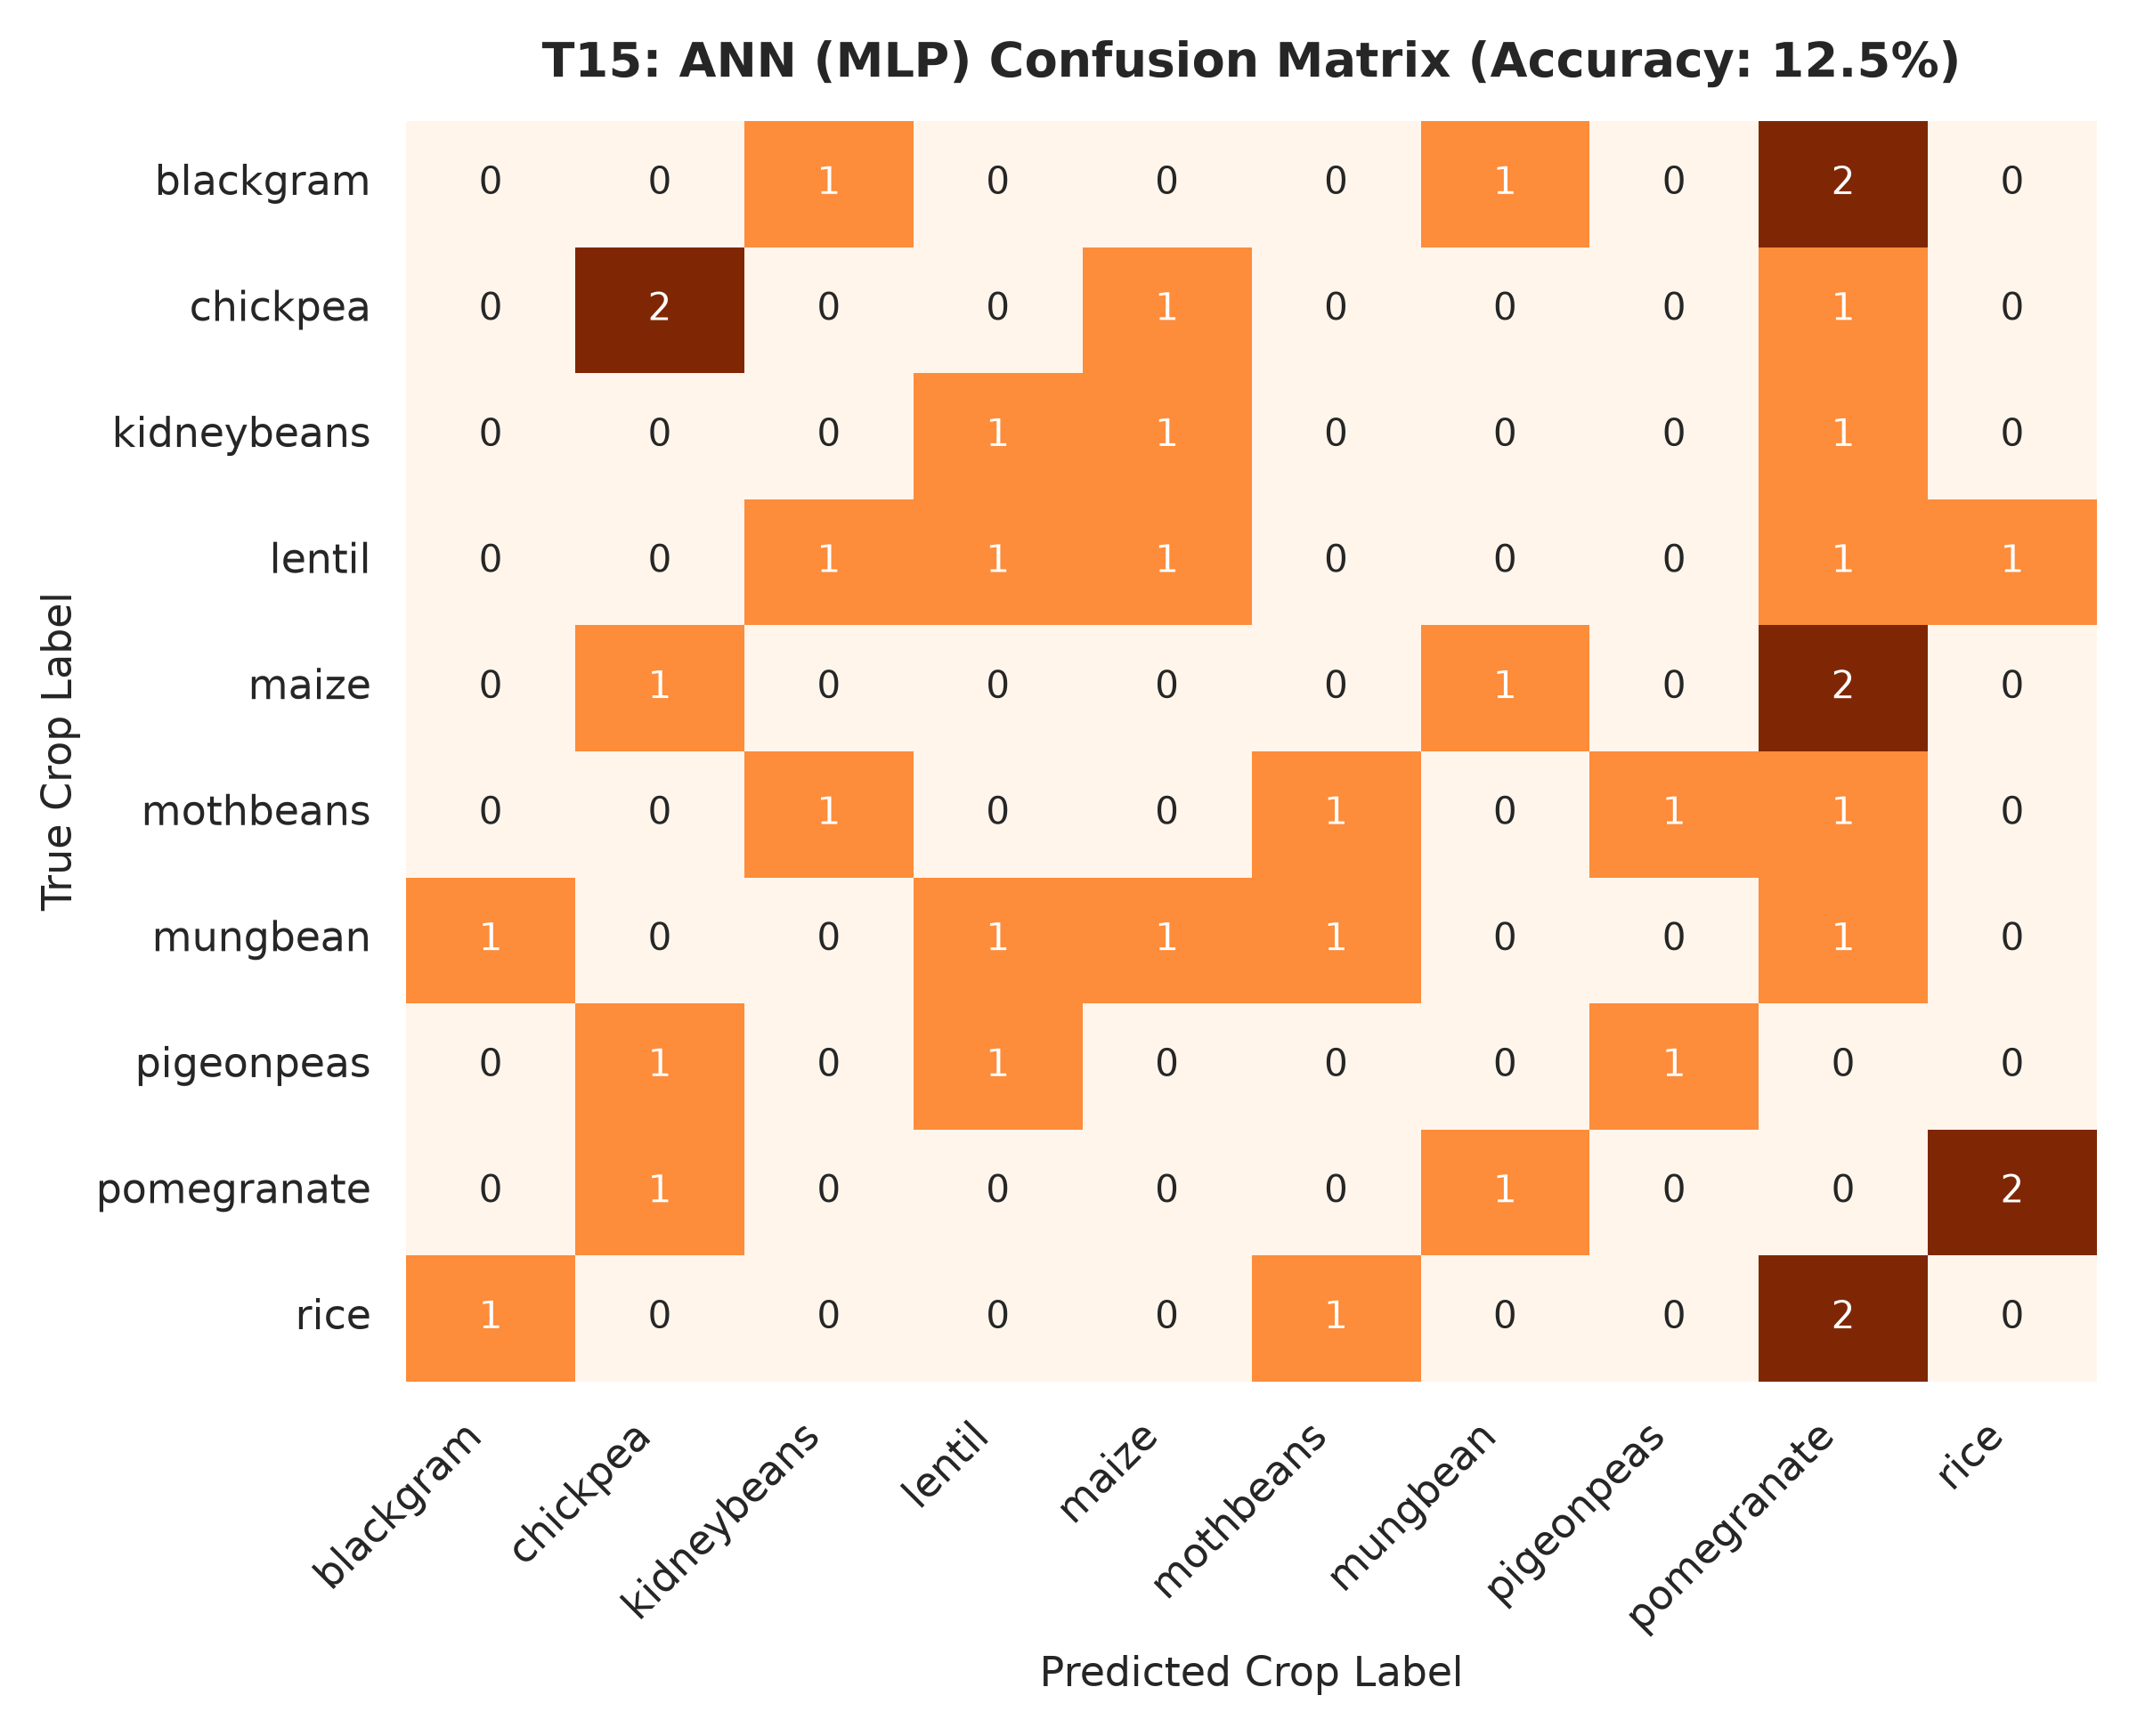

In [5]:
# Step 5: Evaluate MLP Performance & Confusion Matrix
y_pred_mlp = mlp.predict(X_test_s)
train_acc = mlp.score(X_train_s, y_train)
test_acc = accuracy_score(y_test, y_pred_mlp)

print(f"MLP Train Accuracy: {train_acc:.2%}")
print(f"MLP Test Accuracy:  {test_acc:.2%}\n")
print("=== Classification Report ===")
print(classification_report(y_test, y_pred_mlp, target_names=classes, zero_division=0))

cm_mlp = confusion_matrix(y_test, y_pred_mlp)
plt.figure(figsize=(8, 6.5), dpi=300)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f"T15: ANN (MLP) Confusion Matrix (Accuracy: {test_acc:.1%})", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Crop Label", fontsize=11)
plt.ylabel("True Crop Label", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


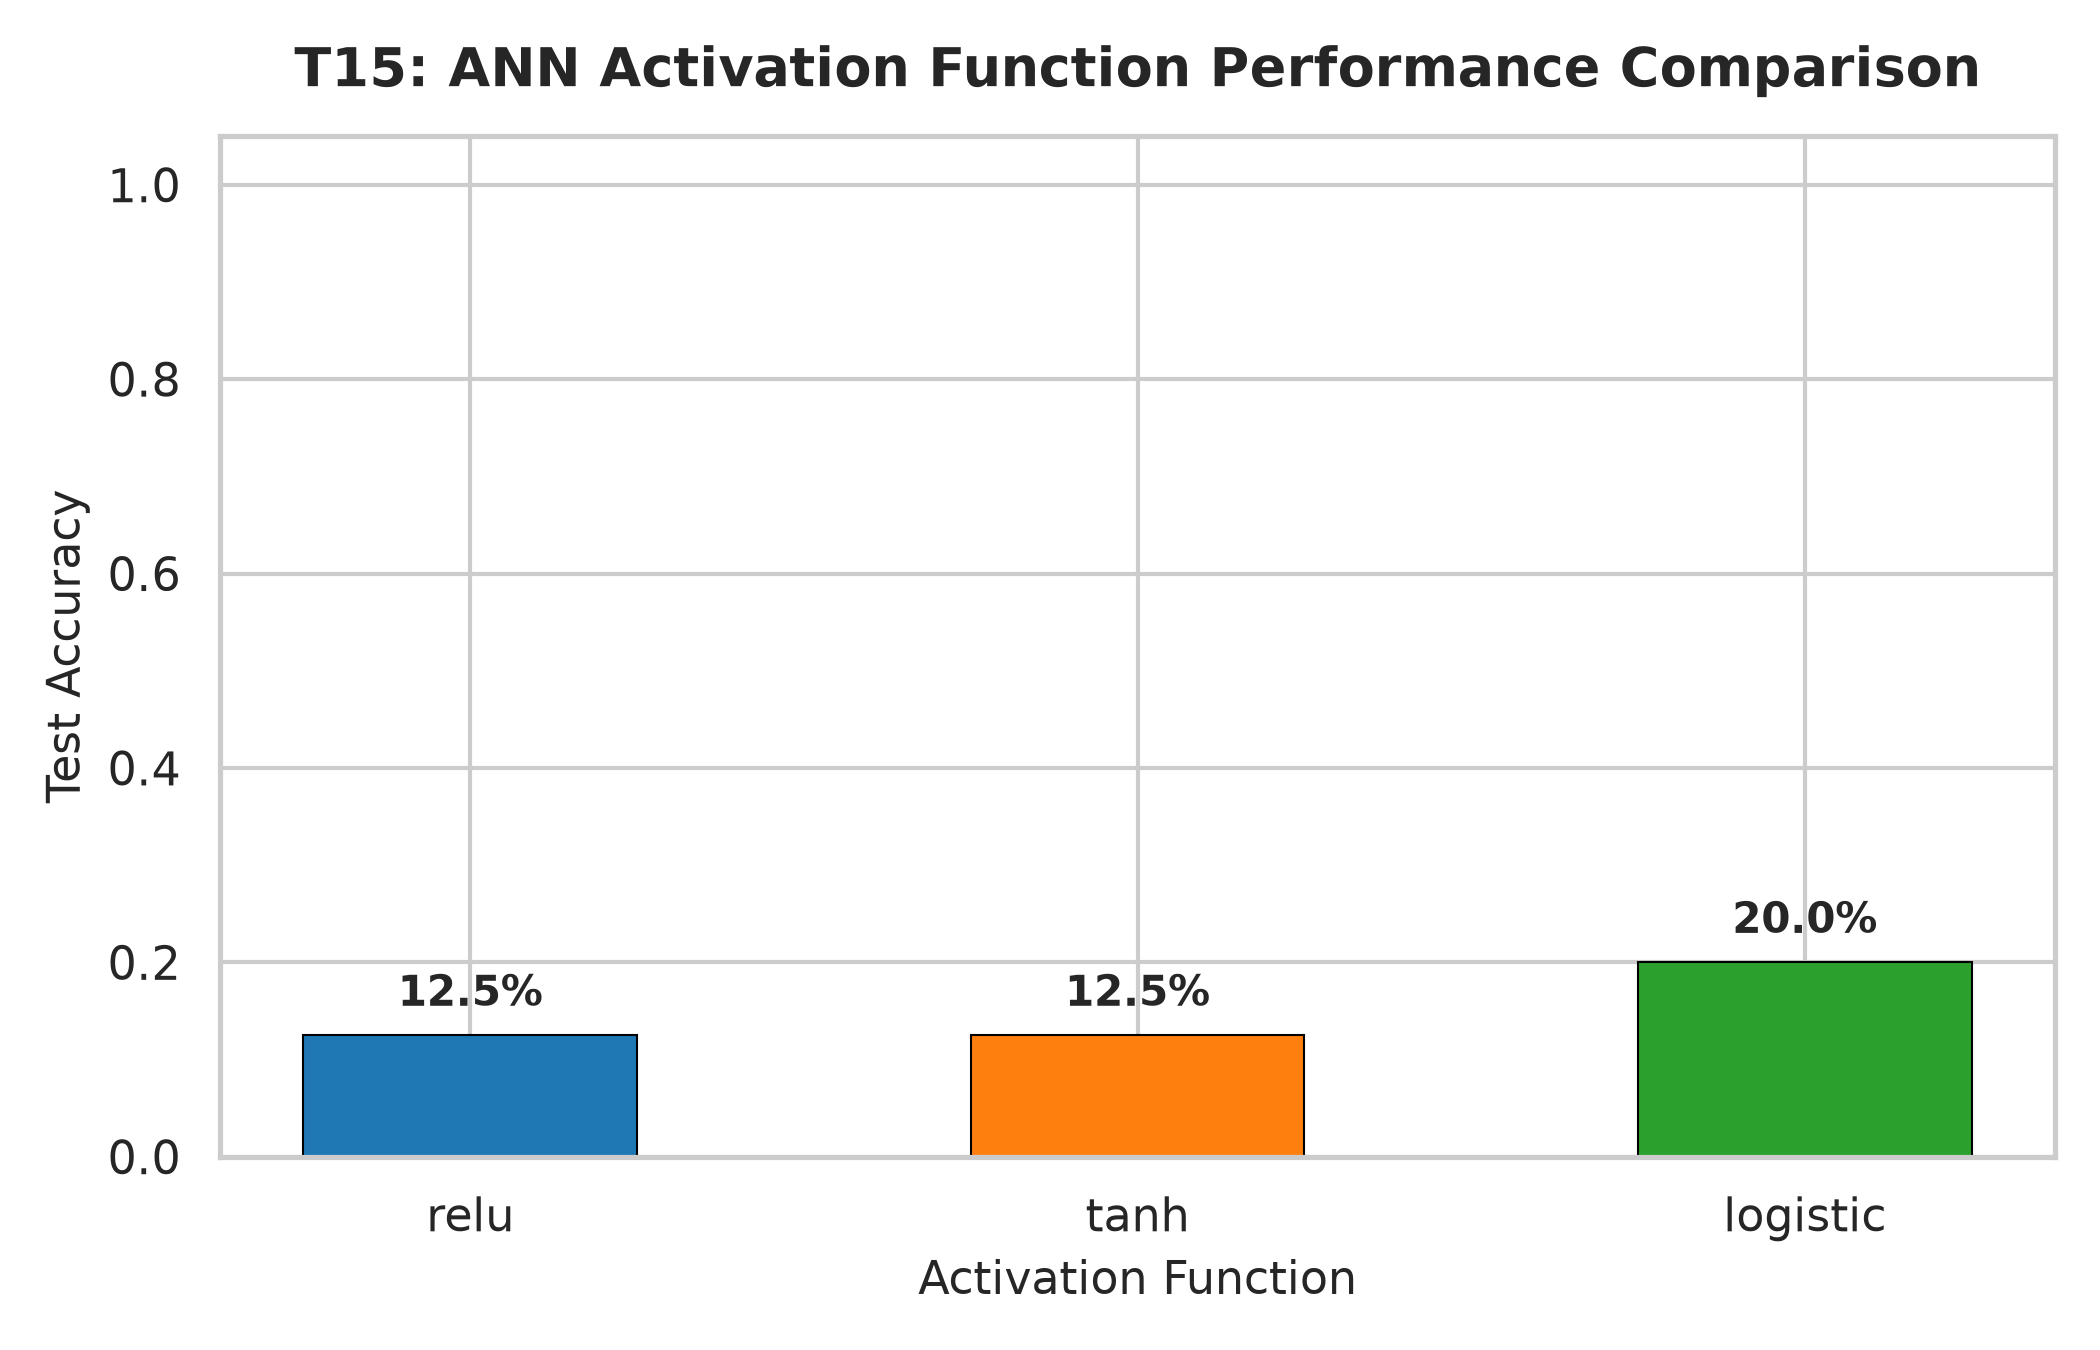

In [6]:
# Step 6: Benchmark Activation Functions
act_funcs = ['relu', 'tanh', 'logistic']
act_accs = []
for act in act_funcs:
    m = MLPClassifier(hidden_layer_sizes=(64, 32), activation=act, solver='adam', max_iter=500, random_state=42)
    m.fit(X_train_s, y_train)
    act_accs.append(m.score(X_test_s, y_test))

plt.figure(figsize=(7, 4.5), dpi=300)
bars = plt.bar(act_funcs, act_accs, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', linewidth=0.5, width=0.5)
plt.title("T15: ANN Activation Function Performance Comparison", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Activation Function", fontsize=11)
plt.ylabel("Test Accuracy", fontsize=11)
plt.ylim(0, 1.05)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.1%}", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


Model Train Accuracy Test Accuracy Macro Precision Macro Recall Macro F1-Score
            Decision Tree (T13)         37.50%         7.50%           4.44%        8.33%          5.42%
            Random Forest (T14)        100.00%         7.50%           5.00%        6.50%          5.49%
Artificial Neural Network (T15)        100.00%        12.50%          14.83%       12.83%         13.52%


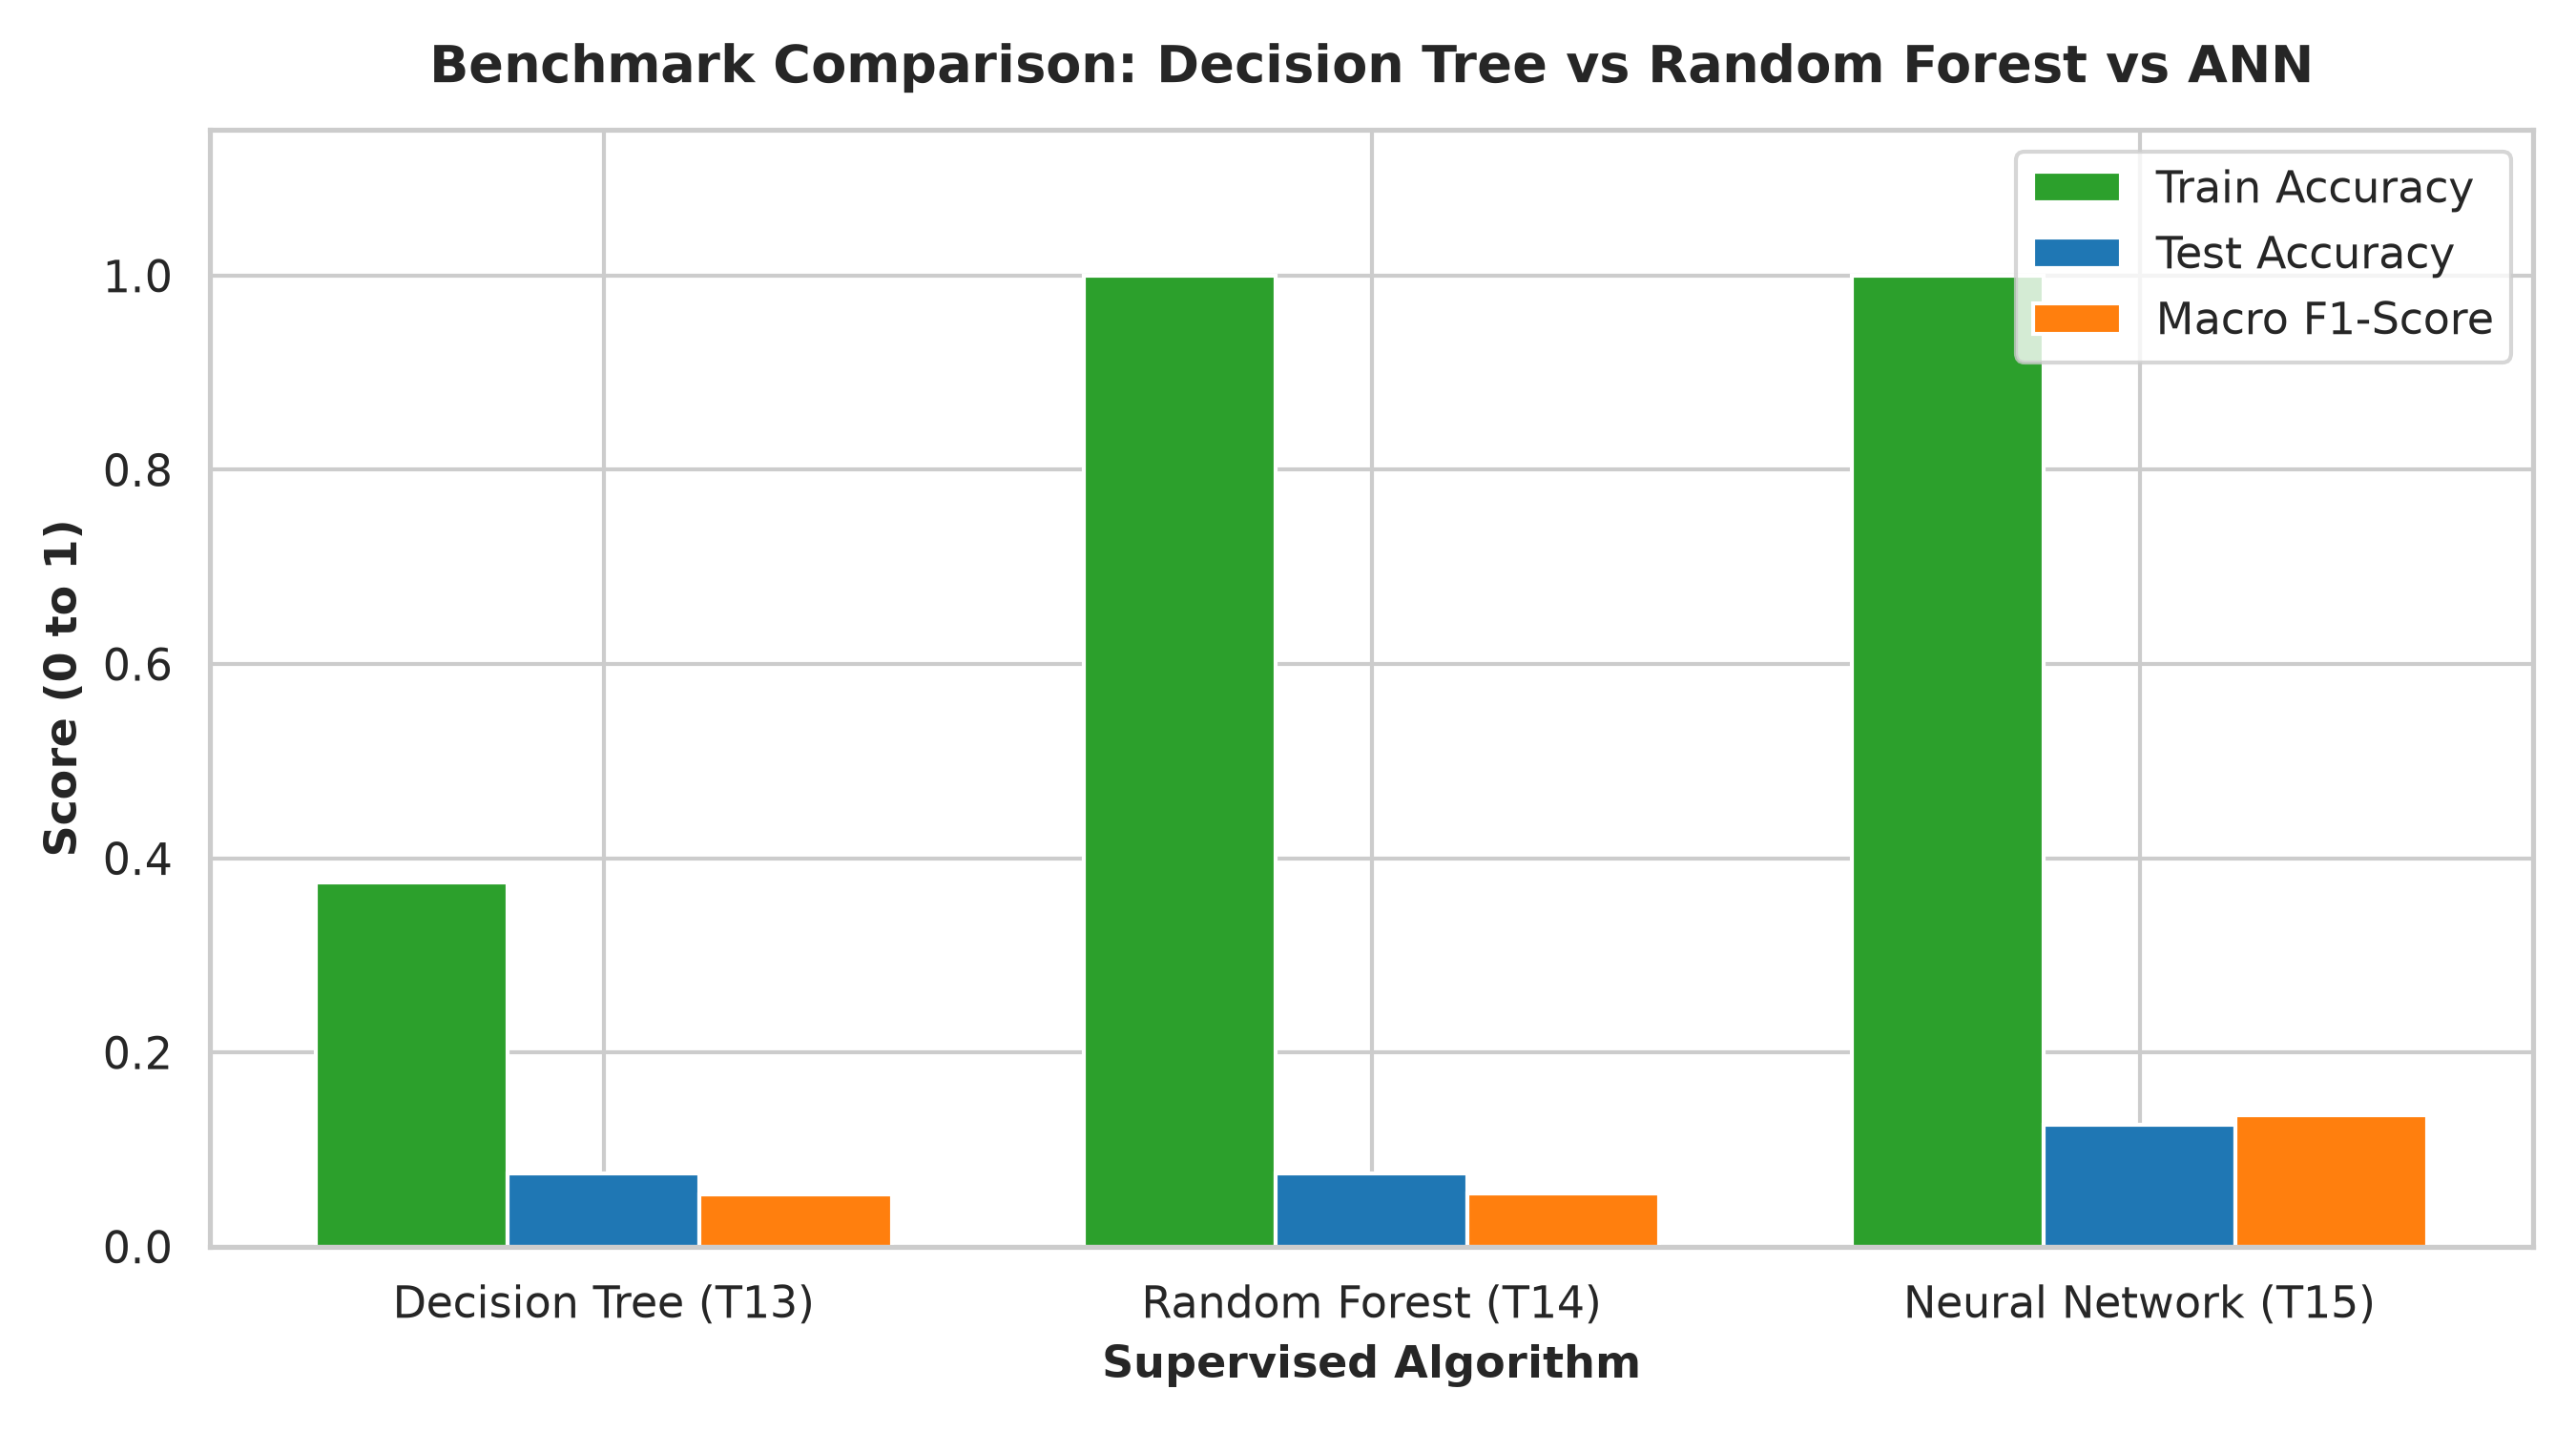

In [7]:
# Step 7: Master Comparison Benchmark (Decision Tree vs Random Forest vs ANN)
comp_df = pd.DataFrame(metrics['summary'])
display(comp_df)


### 🧠 Viva Voce & Conceptual Questions (T15):
1. **Q: Why is feature scaling mandatory before training Artificial Neural Networks?**
   - **A:** Neural networks optimize weights via gradient descent:
   $$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$
   If features have unequal scales, the error surface forms elongated, steep ravines, causing gradient oscillations and slow or failed convergence. Scaling ensures a spherical loss surface for rapid, stable descent.
2. **Q: What is the role of non-linear activation functions (like ReLU)?**
   - **A:** Without non-linear activations, composing multiple linear layers $W_2(W_1 X + b_1) + b_2$ simply collapses mathematically into a single linear regression $(W_2 W_1) X + (W_2 b_1 + b_2)$. Activation functions like ReLU ($\max(0, z)$) introduce non-linearity, enabling ANNs to serve as universal function approximators.
3. **Q: How does the Adam optimizer differ from standard Stochastic Gradient Descent (SGD)?**
   - **A:** Adam (Adaptive Moment Estimation) maintains both exponentially decaying moving averages of past gradients (first moment / momentum) and past squared gradients (second moment / uncentered variance), computing individual adaptive learning rates for each parameter.
